# Plotting strait transports and strait topography in ACCESS-OM3 and ACCESS-OM2

Based on https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/strait_transports/strait_transports.ipynb

Related issues
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/16
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/41
- https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/1

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
# esm_file = "/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test4-rerun-099ed2b5/datastore.json"
# esm_file = "/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5test-67872f64/datastore.json"
esm_file = "/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json"
# esm_file = "/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json"
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/"
nbname = "StraitTransports.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
import intake
from dask.distributed import Client
import matplotlib.pyplot as plt
import cmocean as cm
import cftime
import numpy as np
import xarray as xr

In [5]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [6]:
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()   # no-op on healthy conda envs
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
print(client.dashboard_link)
client

http://127.0.0.1:8787/status


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40539,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35025,Total threads: 1
Dashboard: http://127.0.0.1:38659/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:41435,


In [7]:
plotmaps = False  # whether to plot maps and transects of all straits

In [8]:
IAF = esm_file.find('iaf') > 0
IAF

False

## Define strait names, locations and obs

In [9]:
# Strait locations for ACCESS-OM3: [minlon, maxlon, minlat, maxlat]
# Add as many as you like, but they must be zonal or meridional
om3straits = {
    '25km': {
            'Makassar Strait':     [115-360, 119.5-360,  -2.87, -2.87],  # INSTANT, Gordon et al. 2008 http://dx.doi.org/10.1029/2008GL036372
            'Lifamatola Passage':  [124.5-360, 127.9-360,  -1.6, -1.6],  # NB: significantly shifted from obs to span resolved land INSTANT, van Aken et al. (2009) http://dx.doi.org/10.1016/j.dsr.2009.02.001
            'Lombok Strait':       [-244.8, -243.5,  -8.5, -8.5],
            'Ombai Strait':        [-235.0, -235.0,  -9.21, -8.3],
            'Timor Strait':        [123-360, 123-360, -11.7, -10.7],
            'Timor Strait (full)': [123-360, 123-360, -17.5, -10.7],
            'Leti Strait':         [127-360, 130-360, -8.4, -8.4],
            'Karimata Strait':     [112-360, 112-360, -7.25, -3],
            'ITF South':           [114-360, 138-360, -8.2, -8.2],
            'ITF North':           [115-360, 133-360,  -2.87, -2.87],
            'Torres Strait':       [142.5-360, 142.5-360, -12, -8],
            'Drake Passage':       [-69.9,   -69.9,  -71.6, -51.0],
            'Bering Strait':       [-172,     -167,   65.8,  65.8],
            'Denmark Strait':      [-42,       -22,   65.8,  65.8],
            'East Taiwan Channel': [-238.3,   -236,   24.4,  24.4],  # WOCE PCM-1 array between Taiwan and Iriomote, JohnsLeeZhangZantoppLiuYang2001a http://dx.doi.org/10.1175/1520-0485(2001)031<1031:TKEOTM>2.0.CO;2
            'Florida Current':     [-81,     -78.8,   26.7,  26.7],  # MeinenBaringerGarcia2010a http://dx.doi.org/10.1016/j.dsr.2010.04.001
            'Bosphorus':           [28.5, 29.2, 41.15, 41.15],
            'Gibraltar':           [-5.5, -5.5, 35.5, 36.5, ],
            'Labrador-Greenland, 60°N': [-64.5, -44, 60, 60],  # Sort-of OSNAP-West
            'Greenland-Norway, 60°N': [-44, 8, 60, 60],  # Sort-of OSNAP-East
            },
    # Coordinates for the coarser 100km ACCESS-OM3 grid.
    # Checked directly against the 100km deptho field plus the plotmaps=True
    # depth+GEBCO transect maps: most straits from the 25km set still resolve
    # fine (>=2 wet cells) unchanged, but four needed attention --
    # - Ombai Strait, Florida Current, Gibraltar: only 1 resolved wet cell
    #   with the 25km box (transect mostly on land) -- widened here.
    # - Bosphorus: fully land-blocked (0 wet cells) at 100km -- omitted
    #   entirely, matching how om2straits already excludes it from its own
    #   coarsest ('1deg') family for the same reason.
    '100km': {
            'Makassar Strait':     [115-360, 119.5-360,  -2.87, -2.87],
            'Lifamatola Passage':  [124.5-360, 127.9-360,  -1.6, -1.6],
            'Lombok Strait':       [-244.8, -243.5,  -8.5, -8.5],
            'Ombai Strait':        [-235.0, -235.0,  -9.9, -8.1],  # widened from -9.21,-8.3 (1 wet cell)
            'Timor Strait':        [123-360, 123-360, -11.7, -10.7],
            'Timor Strait (full)': [123-360, 123-360, -17.5, -10.7],
            'Leti Strait':         [127-360, 130-360, -8.4, -8.4],
            'Karimata Strait':     [112-360, 112-360, -7.25, -3],
            'ITF South':           [114-360, 138-360, -8.2, -8.2],
            'ITF North':           [115-360, 133-360,  -2.87, -2.87],
            'Torres Strait':       [142.5-360, 142.5-360, -12, -8],
            'Drake Passage':       [-69.9,   -69.9,  -71.6, -51.0],
            'Bering Strait':       [-172,     -167,   65.8,  65.8],
            'Denmark Strait':      [-42,       -22,   65.8,  65.8],
            'East Taiwan Channel': [-238.3,   -236,   24.4,  24.4],
            'Florida Current':     [-81,     -76,   26.7,  26.7],  # widened from -78.8 (1 wet cell); further extended to -76 per request
            'Gibraltar':           [-5.5, -5.5, 35.0, 36.5],  # widened from 35.5,36.5 (1 wet cell)
            'Labrador-Greenland, 60°N': [-64.5, -44, 60, 60],
            'Greenland-Norway, 60°N': [-44, 8, 60, 60],
            # 'Bosphorus' omitted: not resolvable at 100km resolution
            },
}
for model, straits in om3straits.items(): 
    for strait, (minlon, maxlon, minlat, maxlat) in straits.items():
        if (minlon != maxlon) and (minlat != maxlat):
            raise ValueError(f'Error in {model} {strait}: Must have either minlon == maxlon or minlat == maxlat')

In [10]:
# Strait locations for ACCESS-OM2: [minlon, maxlon, minlat, maxlat]
# Add as many as you like, but they must be zonal or meridional
om2straits = {
    '1deg': {
            'Lombok Strait': [-245, -242, -8.33, -8.33],
            'Ombai Strait':  [-237, -237, -10.33, -8.33],
            'Timor Strait':  [-233, -233, -13.9, -9],
            'Drake Passage': [-69.9, -69.9, -71.6, -51.0],
            'North Atlantic, 60°N': [-64, 8, 60, 60],  # Sort-of OSNAP
            'Labrador-Greenland, 60°N': [-64, -44, 60, 60],  # Sort-of OSNAP-West
            'Greenland-Norway, 60°N': [-44, 8, 60, 60],  # Sort-of OSNAP-East
            'East Taiwan Channel':[121.7-360, 125-360, 24.4, 24.4],  # xmax extended by 1deg as in TsengLinChenThompsonBentsenBoningBozecCassouChassignet2016a
            'Florida Current':[-81, -76, 26.7, 26.7], # xmax extended to -76 (further widened, matches om3straits['100km']) # MeinenBaringerGarcia2010a
            },
    '025deg': {
            'Makassar Strait':     [115-360, 119.5-360,  -2.87, -2.87],  # INSTANT, Gordon et al 2008 http://dx.doi.org/10.1029/2008GL036372
            'Lifamatola Passage':  [125-360, 127.7-360,  -1.7,  -1.7],  # NB: significantly shifted from obs to span resolved land INSTANT, van Aken et al. (2009) http://dx.doi.org/10.1016/j.dsr.2009.02.001
            'Lombok Strait':       [-244.7, -243.6, -8.22, -8.22],
            'Ombai Strait':        [-235.5, -235.5, -9.21, -8.47],
            'Timor Strait':        [123-360, 123-360, -11.7, -10.8],  # to match OSNAP; was previously [-233, -233, -13.86, -8.71]
            'Timor Strait (full)': [123-360, 123-360, -17.5, -10.8],  # to match OSNAP; was previously [-233, -233, -13.86, -8.71]
            'Leti Strait':         [127-360, 130-360, -8.4, -8.4],
            'Karimata Strait':     [112-360, 112-360, -7.25, -3],
            'ITF South':           [114-360, 138-360, -8.2, -8.2],
            'ITF North':           [115-360, 133-360,  -2.87, -2.87],
            'Torres Strait':       [142.5-360, 142.5-360, -12, -8],
            'Drake Passage':       [-69.9, -69.9, -71.6, -51.0],
            'Bering Strait':       [-172,     -167,   65.8,  65.8],
            'Denmark Strait':      [-42,       -22,   65.8,  65.8],
            'North Atlantic, 60°N': [-64.5, 8, 60, 60],  # Sort-of OSNAP
            'Labrador-Greenland, 60°N': [-64.5, -44, 60, 60],  # Sort-of OSNAP-West
            'Greenland-Norway, 60°N': [-44, 8, 60, 60],  # Sort-of OSNAP-East
            'East Taiwan Channel': [121.7-360, 124-360, 24.4, 24.4],  # WOCE PCM-1 array between Taiwan and Iriomote (JohnsLeeZhangZantoppLiuYang2001a)
            'Florida Current':     [-81, -78.8, 26.7, 26.7],  # MeinenBaringerGarcia2010a
            'Bosphorus':           [28.5, 29.5, 41.15, 41.15],
            'Gibraltar':           [-5.5, -5.5, 35.5, 36.5, ],
            },
    '01deg': {
            'Lombok Strait': [-244.3, -243.8, -8.37, -8.37],
            'Ombai Strait':  [-234.9, -234.9, -8.86, -8.27],
            'Timor Strait':  [-232.6, -232.6, -13.96, -8.37],
            'Drake Passage': [-69.9, -69.9, -71.6, -51.0],
            'Bering Strait': [-172, -167, 65.8, 65.8],
            'Denmark Strait':[-42, -22, 65.8, 65.8],
            'North Atlantic, 60°N': [-64.5, 8, 60, 60],  # Sort-of OSNAP
            'Labrador-Greenland, 60°N': [-64.5, -44, 60, 60],  # Sort-of OSNAP-West
            'Greenland-Norway, 60°N': [-44, 8, 60, 60],  # Sort-of OSNAP-East
            'East Taiwan Channel':[121.7-360, 124-360, 24.4, 24.4],  # WOCE PCM-1 array between Taiwan and Iriomote (JohnsLeeZhangZantoppLiuYang2001a)
            'Florida Current':[-81, -78.8, 26.7, 26.7],  # MeinenBaringerGarcia2010a
            },
}
for model, straits in om2straits.items(): 
    for strait, (minlon, maxlon, minlat, maxlat) in straits.items():
        if (minlon != maxlon) and (minlat != maxlat):
            raise ValueError(f'Error in {model} {strait}: Must have either minlon == maxlon or minlat == maxlat')

In [11]:
# Pick the resolution-appropriate strait-coordinate family for a given OM2
# experiment (mirrors the om3straits['100km'] pattern) -- e.g. the default
# 0.25deg om2straits box lands on land for a 1-degree-resolution experiment.
def _om2_family(expt):
    if expt.startswith('01deg'):
        return om2straits['01deg']
    elif expt.startswith('1deg'):
        return om2straits['1deg']
    else:
        return om2straits['025deg']

In [12]:
def date(y, m, d):
    return cftime.DatetimeProlepticGregorian(y, m, d)

In [13]:
obs = {  # observed transport (Sv)
# Also see table 3 in GutjahrETAL2019a http://dx.doi.org/10.5194/gmd-12-3241-2019
# table 1 in YangCessi2024a http://dx.doi.org/10.1029/2024JC021463
# TODO: use uncertainties from Gordon et al (2010) p121 for IAF? Seem handwavy? do we want uncertainty or stdev?
            'Makassar Strait': {'Gordon et al. (2008)': {'value': -11.6, 'lo': -11.6-3.3, 'hi':  -11.6+3.3, 'time': [date(2004, 1, 18), date(2006,  11, 27)]}},  # INSTANT, GordonSusantoFfieldHuberPranowoWirasantosa2008a http://dx.doi.org/10.1029/2008GL036372
            # 'Lifamatola Passage': {'van Aken et al. (2009)': {'value': 1.3-2.7, 'lo': (1.3-2.7)-(1.1+1.3), 'hi': (1.3-2.7)+(1.1+1.3), 'time': [date(2004, 1, 26), date(2006,  12, 4)]}},  # combining below and above 1250m; range is 1std assuming 100% correlation; INSTANT, VanAkenBrodjonegoroJaya2009a http://dx.doi.org/10.1016/j.dsr.2009.02.001
            'Lifamatola Passage': {'Gordon et al. (2010)': {'value': 1.4-2.5, 'lo': (1.4-2.5)-1.4*0.5-2.5*0.05, 'hi': (1.4-2.5)+1.4*0.5+2.5*0.05, 'time': [date(2004, 1, 26), date(2006,  12, 4)]}},  # combining below and above 1250m; range is uncertainty from p121 assuming 100% correlation; INSTANT, GordonETAL2010a http://dx.doi.org/10.1016/j.dynatmoce.2009.12.002; also see VanAkenBrodjonegoroJaya2009a http://dx.doi.org/10.1016/j.dsr.2009.02.001
            'Lombok Strait': {'Sprintall et al. (2009)': {'value': -2.6, 'lo': -1.8, 'hi':  -3.2, 'time': [date(2004, 1, 10), date(2005,  6, 15)], 'depth': [0,  300]}},  # time=dates with both moorings; INSTANT, SprintallWijffelsMolcardJaya2009a http://dx.doi.org/10.1029/2008JC005257
            'Ombai Strait':  {'Sprintall et al. (2009)': {'value': -4.9, 'lo': -2.7, 'hi':  -5.0, 'time': [date(2004, 1,  4), date(2006, 12,  6)], 'depth': [0, 1200]}},  # time=dates with both moorings; INSTANT, SprintallWijffelsMolcardJaya2009a http://dx.doi.org/10.1029/2008JC005257
            'Timor Strait':  {'Sprintall et al. (2009)': {'value': -7.5, 'lo': -6.2, 'hi': -10.5, 'time': [date(2004, 1,  1), date(2006, 12, 12)], 'depth': [0, 1890]}},  # time=dates with  all moorings; INSTANT, SprintallWijffelsMolcardJaya2009a http://dx.doi.org/10.1029/2008JC005257
            'Drake Passage': {'Donohue et al. (2016)': {'value': 173.3, 'lo': 173.3-10.7, 'hi': 173.3+10.7, 'time': [date(2007, 11, 10), date(2011, 11, 10)]}},  # day of month is a guess! DonohueTraceyWattsChidichimoChereskin2016a http://dx.doi.org/10.1002/2016GL070319
            'Bering Strait': {'Woodgate (2018)': {'value': 1, 'lo': 0.7, 'hi': 1.2, 'time': [date(2000, 1,  1), date(2015, 1, 1)]}},  # rough climatology for 2000s; was ~0.8Sv prior to that - Woodgate2018a http://dx.doi.org/10.1016/j.pocean.2017.12.007
            # 'Denmark Strait':  {},
            'East Taiwan Channel': {'Johns et al. (2001)': {'value': 21.5, 'lo': 21.5-2.5, 'hi': 21.5+2.5, 'time': [date(1994, 9,  1), date(1996, 5, 1)]}},  # WOCE PCM-1 array between Taiwan and Iriomote, JohnsLeeZhangZantoppLiuYang2001a http://dx.doi.org/10.1175/1520-0485(2001)031<1031:TKEOTM>2.0.CO;2
            'Florida Current': {'Meinen et al. (2010)': {'value': 32.1, 'lo': 32.1-3.3, 'hi': 32.1+3.3, 'time': [date(1982, 1,  1), date(2008, 1, 1)]}},  # range is ±1SD; rough dates from fig2 MeinenBaringerGarcia2010a http://dx.doi.org/10.1016/j.dsr.2010.04.001
            # 'Bosphorus':  {},
            # 'Gibraltar': {},
}

In [14]:
absobs = {  # observed sum of magnitude of transport at all depths (Sv), to assess exchange flows - see https://github.com/ACCESS-NRI/access-om3-configs/issues/1520#issuecomment-5113509298 
            'Gibraltar': {'Jorda et al. (2016)': {'value': 0.84+0.87, 'lo': 0.84+0.87-2*0.11, 'hi': 0.84+0.87+2*0.11, 'time': [date(2004, 10,  1), date(2010, 12, 1)]}}, # range is ±2SD, i.e. assumes inflow and outflow are perfectly correlated, which they aren't; day of month is a guess! from table 2 JordaSanchezRomanGomis2016a http://dx.doi.org/10.1007/s00382-016-3113-8
}

## Load GEBCO

In [15]:
gebco = xr.open_dataset('/g/data/ik11/inputs/GEBCO_2024/GEBCO_2024.nc',
                        chunks='auto')['elevation']

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145559fc8dd0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145559f1cf80>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x145559999220>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14555999a840>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14555999bbc0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1455599b4b60>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14555926a6f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [16]:
def glon(lon):
    """
    Convert MOM longitude (-270 - 90) to GEBCO longitude (-180 - 180)
    """
    if lon < -180:
        return lon+360
    else:
        return lon

In [17]:
def mlon(lon):
    """
    Convert GEBCO longitude (-180 - 180) to MOM longitude (-270 - 90) 
    """
    if lon > 90:
        return lon-360
    else:
        return lon

## Load ACCESS-OM3 data from ESM datastore

In [18]:
if model_name == "ACCESS-CM3":
    catalogs = [esm_file]
else:
    catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/MC_25km_jra_ryf-1.0-beta/experiment_datastore.json',
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',  # superseded
                esm_file,
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',  # superseded
                # '/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json',
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test4-rerun-099ed2b5/datastore.json',
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5test-67872f64/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test-test5-tweaks-dd8d35ed/datastore.json',
            ]
catalogs

['/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json']

In [19]:
from exptdata_access import get_exptname_from_path
datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
datastores

{'MC_8km_jra_ryf-test2-expt-c349f800': <datastore catalog with 32 dataset(s) from 3843 asset(s)>}

In [20]:
# Give the new 100km experiments distinct, high-contrast colors so they
# don't blend into the tab10 colours (brown/pink look too similar
# when overlapping with several other lines).
# The full experiment -> colour mapping (expt_colors) is built after the OM2
# experiment names are defined, below.
highlight_colors = {
    "MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c": "magenta",
}

In [21]:
om3exptname = get_exptname_from_path(esm_file)

# Use the 100km-tuned strait coordinates when the primary experiment is one
# of the 100km configs, so its own maps/transects (and the transect
# quantization below) show the correctly-resolved boxes automatically.
active_om3straits = om3straits['100km'] if "100km" in om3exptname else om3straits['25km']

om3exptname

'MC_8km_jra_ryf-test2-expt-c349f800'

## Load OM3 data

In [22]:
om3varnames = [ 'umo_2d', 'vmo_2d', 'uo', 'vo', 'umo', 'vmo', 'deptho' ]

om3chunks = {"time": -1}
if model_name == "ACCESS-CM3":
    om3chunks = {"time": 1}  # CM3 stores yearly files

om3staticvarnames = [ 'deptho' ]  # workaround - see below

# Not every experiment saves every variable: the 100km configs output only the
# depth-integrated umo_2d/vmo_2d, not the 3d umo/vmo. Skip the experiments that
# lack a variable rather than failing the whole load; downstream plots check
# membership and omit those experiments.
om3vars = dict()
for vname in om3varnames:
    if vname in om3staticvarnames:  # workaround - see below
        continue
    om3vars[vname] = dict()
    for expt, ds in datastores.items():
        found = ds.search(variable=vname)
        if len(found.df) == 0:
            print(f"{expt} has no {vname} - omitted from this variable")
            continue
        om3vars[vname][expt] = found.to_dask(
            xarray_open_kwargs = dict(
                chunks=om3chunks,
                decode_timedelta=True
            )
        )

# workaround for excessive xarray strictness in analysis3-26.02 and analysis3-26.03
# https://forum.access-hive.org.au/t/issues-in-loading-ht-in-latest-conds-envs/6278
for vname in om3staticvarnames:
    om3vars[vname] = dict()
    for expt, ds in datastores.items():
        found = ds.search(variable=vname)
        if len(found.df) == 0:
            print(f"{expt} has no {vname} - omitted from this variable")
            continue
        vpath = found.df.loc[0, 'path']
        om3vars[vname][expt] = ds.search(path=vpath).to_dask(
                xarray_open_kwargs = dict(
                    chunks=om3chunks,
                    decode_timedelta=True
                )
            )

if model_name == "ACCESS-CM3":
    for vname in ["umo_2d", "vmo_2d"]:
        for expt in om3vars[vname]:
            om3vars[vname][expt] = om3vars[vname][expt].chunk({"time": 24})  # rolling(12) needs chunks > window

# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3vars.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass

if IAF or model_name == "ACCESS-CM3":  # common calendar for obs overlays
    for vname, d in om3vars.items():
        for expt, ds in d.items():
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

# RYF spin-up runs use a synthetic calendar (e.g. starting ~1900s) unrelated to
# real forcing dates, so their time axis doesn't overlap the IAF experiments'
# real dates at all -- relabel it onto the primary experiment's real time axis
# so it plots on the same timescale as the others (same technique used above
# for the ACCESS-CM3/CM2 spin-up relabeling).
_ryf_expt = 'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c'
if _ryf_expt in datastores:
    _ref_time = om3vars['umo_2d'][om3exptname].time
    for vname, d in om3vars.items():
        if vname in om3staticvarnames or _ryf_expt not in d:
            continue
        ds = d[_ryf_expt]
        n = min(ds.sizes['time'], _ref_time.sizes['time'])
        d[_ryf_expt] = (ds.isel(time=slice(None, n))
                          .assign_coords(time=('time', _ref_time.isel(time=slice(None, n)).values)))

# define variables for om3exptname data (for map and transect plots)
# (skip variables om3exptname doesn't save, e.g. 3d umo/vmo in the 100km configs)
for varname, d in om3vars.items():
    if om3exptname in d:
        exec(varname + f'=d["{om3exptname}"]')

In [23]:
# OM3 time range, used to restrict time range of OM2 data - BUG: not compatible with cfdatetime in IAF OM2 data
datestop = umo_2d.time.values[-1] # final date in data
datelist = list(cftime.to_tuple(datestop))
datelist[0] -= 30  # last 30 years
datestart = cftime.datetime(*datelist, calendar=datestop.calendar)
timeslice = slice(datestart, datestop)
# String form for comparing against OM2 time coords, which may retain a
# different (e.g. GREGORIAN/datetime64) calendar than OM3's cftime timeslice
# above even after convert_calendar() -- string-based slicing works uniformly
# across cftime and datetime64 time indexes.
timeslice_str = slice(datestart.strftime('%Y-%m-%d'), datestop.strftime('%Y-%m-%d'))
# timeslice = slice(umo_2d.time.values[0], umo_2d.time.values[-1])  # all available
timeslice

slice(cftime.datetime(1879, 12, 16, 12, 0, 0, 0, calendar='noleap', has_year_zero=True), cftime.DatetimeNoLeap(1909, 12, 16, 12, 0, 0, 0, has_year_zero=True), None)

## Quantise OM3 transect locations to relevant grid

In [24]:
straits = active_om3straits
for strait, (xmin, xmax, ymin, ymax) in straits.items():
    if xmin == xmax:
        xmin = xmax = umo_2d.umo_2d.sel(xq=xmin, method='nearest').xq.values
    elif ymin == ymax:
        ymin = ymax = vmo_2d.vmo_2d.sel(yq=ymin, method='nearest').yq.values
    straits[strait] = [xmin, xmax, ymin, ymax]

## Plot OM3 maps

In [25]:
# plot maps of depth at transect locations, with GEBCO coastline
# BUG: GEBCO will be plotted incorrectly in tripolar region
m = 2.5 # margin (degrees)
if plotmaps:
    for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        h = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=slice(ymin-m, ymax+m)).load()
        g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(ymin-m, ymax+m)).load()
        g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
        h.plot(cmap='jet_r', vmin=0, vmax=g.max())
        g.plot.contour(vmin=0, vmax=0, levels = 1, colors='black', alpha=0.5)
        if xmin == xmax:
            h1 = deptho.deptho.sel(xh=xmin, method='ffill').sel(yh=slice(ymin-m, ymax+m)).xh.values
            h2 = deptho.deptho.sel(xh=xmin, method='bfill').sel(yh=slice(ymin-m, ymax+m)).xh.values
            plt.plot([h1, h1], [ymin, ymax], 'k-', linewidth=2)
            plt.plot([h2, h2], [ymin, ymax], 'k--', linewidth=2)
        else:
            h1 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=ymin, method='ffill').yh.values
            h2 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=ymin, method='bfill').yh.values
            plt.plot([xmin, xmax], [h1, h1], 'k-', linewidth=2)
            plt.plot([xmin, xmax], [h2, h2], 'k--', linewidth=2)
        plt.plot([xmin, xmax], [ymin, ymax], color='green', linewidth=4, alpha=0.6)
        plt.title(f"{strait} {h.name} in ACCESS-OM3\n{om3exptname}")

In [26]:
# plot maps of GEBCO depth at transect locations, with GEBCO coastline
# BUG: GEBCO will be plotted incorrectly in tripolar region
m = 2.5 # margin (degrees)
if plotmaps:
    for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(ymin-m, ymax+m)).load()
        g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
        g.plot(cmap='jet_r', vmin=0, vmax=g.max(), extend='neither')
        g.plot.contour(vmin=0, vmax=0, levels = 1, colors='black', alpha=0.5)
        if xmin == xmax:
            h1 = deptho.deptho.sel(xh=xmin, method='ffill').sel(yh=slice(ymin-m, ymax+m)).xh.values
            h2 = deptho.deptho.sel(xh=xmin, method='bfill').sel(yh=slice(ymin-m, ymax+m)).xh.values
            plt.plot([h1, h1], [ymin, ymax], 'k-', linewidth=2)
            plt.plot([h2, h2], [ymin, ymax], 'k--', linewidth=2)
        else:
            h1 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=ymin, method='ffill').yh.values
            h2 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=ymin, method='bfill').yh.values
            plt.plot([xmin, xmax], [h1, h1], 'k-', linewidth=2)
            plt.plot([xmin, xmax], [h2, h2], 'k--', linewidth=2)
        plt.plot([xmin, xmax], [ymin, ymax], color='green', linewidth=4, alpha=0.6)
        plt.title(f"{strait} GEBCO2024 depth")

In [27]:
# plot maps of transport at transect locations, with GEBCO coastline
# BUG: GEBCO will be plotted incorrectly in tripolar region
m = 2.5 # margin (degrees)
if plotmaps:
    for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        if xmin == xmax:
            vel = umo_2d.umo_2d.sel(xq=slice(xmin-m, xmax+m)).sel(yh=slice(ymin-m, ymax+m))
        else:
            vel = vmo_2d.vmo_2d.sel(xh=slice(xmin-m, xmax+m)).sel(yq=slice(ymin-m, ymax+m))
        velmean = vel.sel(time=timeslice).mean('time').load()
        velmean.plot()
        g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(ymin-m, ymax+m)).load()
        g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
        g.plot.contour(vmin=0, vmax=0, levels = 1, colors='black', alpha=0.5)
        if xmin == xmax:
            h1 = deptho.deptho.sel(xh=xmin, method='ffill').sel(yh=slice(ymin-m, ymax+m)).xh.values
            h2 = deptho.deptho.sel(xh=xmin, method='bfill').sel(yh=slice(ymin-m, ymax+m)).xh.values
            plt.plot([h1, h1], [ymin, ymax], 'k-', linewidth=2)
            plt.plot([h2, h2], [ymin, ymax], 'k--', linewidth=2)
        else:
            h1 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=ymin, method='ffill').yh.values
            h2 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=ymin, method='bfill').yh.values
            plt.plot([xmin, xmax], [h1, h1], 'k-', linewidth=2)
            plt.plot([xmin, xmax], [h2, h2], 'k--', linewidth=2)
        plt.plot([xmin, xmax], [ymin, ymax], color='green', linewidth=4, alpha=0.6)
        plt.title(f"{strait} {vel.name} in ACCESS-OM3\n{om3exptname} {vel.time.values[0].strftime('%Y-%m-%d')} - {vel.time.values[-1].strftime('%Y-%m-%d')} mean")

## Plot OM3 transects

In [28]:
# plot vertical slices at transect locations, with range of GEBCO bathymetry over grid cell width
# BUG: GEBCO will be plotted incorrectly in tripolar region
m = 1.5  # margin (degrees)
res = 0.25  # nominal grid resolution (degrees) - BUG: too large in latitude except at equator
if plotmaps:
    for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        if xmin == xmax:
            vel = uo.uo.sel(xq=xmin, method='nearest').sel(yh=slice(ymin-m, ymax+m))
            velmean = vel.sel(time=timeslice).mean('time').load()
            velmean.plot()
            g = -gebco.sel(lon=slice(glon(vel.xq.values-res/2), glon(vel.xq.values+res/2))).sel(lat=slice(ymin-m, ymax+m)).load()
            g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
            plt.gca().fill_between(g.lat.values, g.min(dim='lon'), g.max(dim='lon'), color='black', edgecolor=None, alpha=0.2)
            h1 = deptho.deptho.sel(xh=vel.xq.values, method='ffill').sel(yh=slice(ymin-m, ymax+m))
            h2 = deptho.deptho.sel(xh=vel.xq.values, method='bfill').sel(yh=slice(ymin-m, ymax+m))
            plt.plot(h1.yh, h1.fillna(0), 'k-', linewidth=2)
            plt.plot(h2.yh, h2.fillna(0), 'k--', linewidth=2)
            zlim = 2*plt.gca().get_ylim()[1]
            plt.plot([ymin, ymin, ymax, ymax], [0, zlim, zlim, 0],
                color='green', linewidth=4, alpha=0.6)
        else:
            vel = vo.vo.sel(xh=slice(xmin-m, xmax+m)).sel(yq=ymin, method='nearest')
            velmean = vel.sel(time=timeslice).mean('time').load()
            velmean.plot()
            g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(vel.yq.values-res/2, vel.yq.values+res/2)).load()
            g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
            plt.gca().fill_between(g.lon.values, g.min(dim='lat'), g.max(dim='lat'), color='black', edgecolor=None, alpha=0.2)
            h1 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=vel.yq.values, method='ffill')
            h2 = deptho.deptho.sel(xh=slice(xmin-m, xmax+m)).sel(yh=vel.yq.values, method='bfill')
            plt.plot(h1.xh, h1.fillna(0), 'k-', linewidth=2)
            plt.plot(h2.xh, h2.fillna(0), 'k--', linewidth=2)
            zlim = 2*plt.gca().get_ylim()[1]
            plt.plot([xmin, xmin, xmax, xmax], [0, zlim, zlim, 0],
                color='green', linewidth=4, alpha=0.6)
        plt.gca().set_ylim([None, 1.1*np.max(g)])
        plt.gca().invert_yaxis()
        plt.title(f"{strait} {vel.name} in ACCESS-OM3\n{om3exptname} {vel.time.values[0].strftime('%Y-%m-%d')} - {vel.time.values[-1].strftime('%Y-%m-%d')} mean")

## Load ACCESS-OM2 data from ACCESS-NRI Catalog

### BUG: GM and submeso transport neglected!


In [29]:
catalog = intake.cat.access_nri

In [30]:
if model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    om2exptname = 'cj877'  # CM2 control archive on /g/data/p73 (as in pPV.ipynb)
    om2exptnames = [om2exptname]  # single-entry, so downstream loops work unchanged

    def load_cm2(pattern, n_months=600, tchunk=6):
        """Open cj877 files; keep FIRST n_months (6 months per file) for spin-up comparison with CM3."""
        import glob
        files = sorted(glob.glob('/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/' + pattern))
        if len(files) > 1:
            files = files[:((n_months + 5) // 6)]
        ds = xr.open_mfdataset(files, combine="by_coords", parallel=True,
                               chunks={"time": 6}, decode_timedelta=True, use_cftime=True,
                               data_vars="minimal", coords="minimal", compat="override")
        return ds.chunk({"time": tchunk})
else:
    data_name = 'ACCESS-OM2'
    if IAF:
        om2exptname = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2exptname = '025deg_jra55_ryf9091_gadi'

    # Additional OM2 comparison experiments (plotted alongside om2exptname above).
    om2exptnames = [om2exptname, '01deg_jra55v140_iaf_cycle4_jra55v150_extension']

In [31]:
# One fixed colour per experiment, used for every line (thin and rolling mean) of that
# experiment in all the plots below, so an experiment looks the same in every figure.
# Order is deterministic (OM2 experiments, then OM3/CM3 datastores); highlight_colors take
# precedence and the rest are taken from tab10 in order, skipping the pink that is too
# close to magenta. Observations are always black.
_tab10 = [c for i, c in enumerate(plt.get_cmap('tab10').colors) if i != 6]  # skip pink
_names = list(om2exptnames) + [e for e in datastores if e not in om2exptnames]
_free = [c for c in _tab10 if c not in highlight_colors.values()]
expt_colors = dict(highlight_colors)
for _i, _e in enumerate([e for e in _names if e not in highlight_colors]):
    expt_colors[_e] = _free[_i % len(_free)]
expt_colors


{'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c': 'magenta',
 '025deg_jra55_ryf9091_gadi': (0.12156862745098039,
  0.4666666666666667,
  0.7058823529411765),
 '01deg_jra55v140_iaf_cycle4_jra55v150_extension': (1.0,
  0.4980392156862745,
  0.054901960784313725),
 'MC_8km_jra_ryf-test2-expt-c349f800': (0.17254901960784313,
  0.6274509803921569,
  0.17254901960784313)}

In [32]:
if model_name == "ACCESS-CM3":
    tx_trans_int_z = {om2exptname: load_cm2("ocean-2d-tx_trans_int_z-1-monthly-mean-ym_*.nc", tchunk=24)}  # rolling(12) needs chunks > window
else:
    tx_trans_int_z = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='tx_trans_int_z',frequency="1mon")
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        tx_trans_int_z[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [33]:
if model_name == "ACCESS-CM3":
    ty_trans_int_z = {om2exptname: load_cm2("ocean-2d-ty_trans_int_z-1-monthly-mean-ym_*.nc", tchunk=24)}  # rolling(12) needs chunks > window
else:
    ty_trans_int_z = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='ty_trans_int_z',frequency="1mon")
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        ty_trans_int_z[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [34]:
if model_name == "ACCESS-CM3":
    tx_trans = {om2exptname: load_cm2("ocean-2d-tx_trans-1-monthly-mean-ym_*.nc", tchunk=24)}  # rolling(12) needs chunks > window
else:
    tx_trans = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='tx_trans',frequency="1mon")
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        tx_trans[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [35]:
if model_name == "ACCESS-CM3":
    ty_trans = {om2exptname: load_cm2("ocean-2d-ty_trans-1-monthly-mean-ym_*.nc", tchunk=24)} # rolling(12) needs chunks > window
else:
    ty_trans = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='ty_trans',frequency="1mon")
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        ty_trans[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [36]:
if model_name == "ACCESS-CM3":
    u = {om2exptname: load_cm2("ocean-3d-u-1-monthly-mean-ym_*.nc")}
else:
    u = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='u',frequency="1mon")
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        u[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [37]:
if model_name == "ACCESS-CM3":
    v = {om2exptname: load_cm2("ocean-3d-v-1-monthly-mean-ym_*.nc")}
else:
    v = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='v',frequency="1mon")
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        v[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [38]:
if model_name == "ACCESS-CM3":
    ht = {om2exptname: load_cm2("ocean-2d-ht.nc")}
else:
    ht = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='ht',frequency="fx")
        var = catalog[_expt].search(path=var.df.loc[0, 'path'])  # workaround - see https://forum.access-hive.org.au/t/issues-in-loading-ht-in-latest-conds-envs/6278
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        ht[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [39]:
if model_name == "ACCESS-CM3":
    hu = {om2exptname: load_cm2("ocean-2d-hu.nc")}
else:
    hu = {}
    for _expt in om2exptnames:
        var = catalog[_expt].search(variable='hu',frequency="fx")
        var = catalog[_expt].search(path=var.df.loc[0, 'path'])  # workaround - see https://forum.access-hive.org.au/t/issues-in-loading-ht-in-latest-conds-envs/6278
        var.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
        hu[_expt] = var.to_dask(
                    xarray_open_kwargs=dict(
                    chunks={"time": -1},
                    decode_timedelta=True,
                    use_cftime=True)
        )

In [40]:
if IAF:
    for _expt in om2exptnames:
        tx_trans_int_z[_expt] = tx_trans_int_z[_expt].convert_calendar("proleptic_gregorian", use_cftime=True)
        ty_trans_int_z[_expt] = ty_trans_int_z[_expt].convert_calendar("proleptic_gregorian", use_cftime=True)
        tx_trans[_expt] = tx_trans[_expt].convert_calendar("proleptic_gregorian", use_cftime=True)
        ty_trans[_expt] = ty_trans[_expt].convert_calendar("proleptic_gregorian", use_cftime=True)
        u[_expt] = u[_expt].convert_calendar("proleptic_gregorian", use_cftime=True)
        v[_expt] = v[_expt].convert_calendar("proleptic_gregorian", use_cftime=True)

if model_name == "ACCESS-CM3":
    # relabel CM2 spin-up (first months) onto the CM3 axis for spin-up comparison
    _om3t = om3vars['umo_2d'][om3exptname].time
    def _relabel(ds):
        n = min(ds.sizes["time"], _om3t.sizes["time"])
        return (ds.isel(time=slice(None, n))
                  .assign_coords(time=("time", _om3t.isel(time=slice(None, n)).values)))
    tx_trans_int_z = _relabel(tx_trans_int_z)
    ty_trans_int_z = _relabel(ty_trans_int_z)
    tx_trans = _relabel(tx_trans)
    ty_trans = _relabel(ty_trans)
    u = _relabel(u)
    v = _relabel(v)


## Quantise OM2 transect locations to relevant grid

In [41]:
# Quantize against the primary (first) OM2 comparison experiment's own grid.
_tx_ref = tx_trans_int_z[om2exptnames[0]]
_ty_ref = ty_trans_int_z[om2exptnames[0]]

straits = om2straits['025deg']
for strait, (xmin, xmax, ymin, ymax) in straits.items():
    if xmin == xmax:
        xmin = xmax = _tx_ref.tx_trans_int_z.sel(xu_ocean=xmin, method='nearest').xu_ocean.values
    elif ymin == ymax:
        ymin = ymax = _ty_ref.ty_trans_int_z.sel(yu_ocean=ymin, method='nearest').yu_ocean.values
    straits[strait] = [xmin, xmax, ymin, ymax]

## Plot OM2 maps

In [42]:
# plot maps of depth at transect locations, with GEBCO coastline
# BUG: GEBCO will be plotted incorrectly in tripolar region
m = 2.5 # margin (degrees)
if plotmaps:
    _hu_ref = hu[om2exptnames[0]]
    _om2_map_label = om2exptnames[0]
    for strait, (xmin, xmax, ymin, ymax) in om2straits['025deg'].items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        h = _hu_ref.hu.sel(xu_ocean=slice(xmin-m, xmax+m)).sel(yu_ocean=slice(ymin-m, ymax+m)).load()
        g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(ymin-m, ymax+m)).load()
        g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
        h.plot(cmap='jet_r', vmin=0, vmax=g.max())
        g.plot.contour(vmin=0, vmax=0, levels = 1, colors='black', alpha=0.5)
        if xmin == xmax:
            h1 = _hu_ref.hu.sel(xu_ocean=xmin, method='nearest').xu_ocean.values
            plt.plot([h1, h1], [ymin, ymax], 'k--', linewidth=2)
        else:
            h1 = _hu_ref.hu.sel(yu_ocean=ymin, method='nearest').yu_ocean.values
            plt.plot([xmin, xmax], [h1, h1], 'k--', linewidth=2)
        plt.plot([xmin, xmax], [ymin, ymax], color='green', linewidth=4, alpha=0.6)
        plt.title(f"{strait} {h.name} in ACCESS-OM2\n{_om2_map_label}")

In [43]:
# plot maps of transect locations, with GEBCO coastline
# BUG: GEBCO will be plotted incorrectly in tripolar region
# BUG: GM and submeso transport neglected!
m = 2.5 # margin (degrees)
if plotmaps:
    _hu_ref = hu[om2exptnames[0]]
    _tx_ref = tx_trans_int_z[om2exptnames[0]]
    _ty_ref = ty_trans_int_z[om2exptnames[0]]
    _om2_map_label = om2exptnames[0]
    for strait, (xmin, xmax, ymin, ymax) in om2straits['025deg'].items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        if xmin == xmax:
            vel = _tx_ref.tx_trans_int_z.sel(xu_ocean=slice(xmin-m, xmax+m)).sel(yt_ocean=slice(ymin-m, ymax+m))
        else:
            vel = _ty_ref.ty_trans_int_z.sel(xt_ocean=slice(xmin-m, xmax+m)).sel(yu_ocean=slice(ymin-m, ymax+m))
        velmean = vel.sel(time=timeslice).mean('time').load()
        velmean.plot()
        g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(ymin-m, ymax+m)).load()
        g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
        g.plot.contour(vmin=0, vmax=0, levels = 1, colors='black', alpha=0.5)
        if xmin == xmax:
            h1 = _hu_ref.hu.sel(xu_ocean=xmin, method='nearest').xu_ocean.values
            plt.plot([h1, h1], [ymin, ymax], 'k--', linewidth=2)
        else:
            h1 = _hu_ref.hu.sel(yu_ocean=ymin, method='nearest').yu_ocean.values
            plt.plot([xmin, xmax], [h1, h1], 'k--', linewidth=2)
        plt.plot([xmin, xmax], [ymin, ymax], color='green', linewidth=4, alpha=0.6)
        plt.title(f"{strait} {vel.name} in ACCESS-OM2\n{_om2_map_label} {vel.time.values[0].strftime('%Y-%m-%d')} - {vel.time.values[-1].strftime('%Y-%m-%d')} mean")

## Plot OM2 transects

In [44]:
# plot vertical slices at transect locations, with range of GEBCO bathymetry over grid cell width
# BUG: GEBCO will be plotted incorrectly in tripolar region
# BUG: GM and submeso transport neglected!
m = 1.5  # margin (degrees)
res = 0.25  # nominal grid resolution (degrees) - BUG: too large in latitude except at equator
if plotmaps:
    _hu_ref = hu[om2exptnames[0]]
    _u_ref = u[om2exptnames[0]]
    _v_ref = v[om2exptnames[0]]
    _om2_map_label = om2exptnames[0]
    for strait, (xmin, xmax, ymin, ymax) in om2straits['025deg'].items():
        print(strait)
        fig, ax = plt.subplots(nrows=1, ncols=1)
        ax.set_facecolor('gray')  # gray land points
        if xmin == xmax:
            vel = _u_ref.u.sel(xu_ocean=xmin, method='nearest').sel(yu_ocean=slice(ymin-m, ymax+m))
            velmean = vel.sel(time=timeslice).mean('time').load()
            velmean.plot()
            g = -gebco.sel(lon=slice(glon(vel.xu_ocean.values-res/2), glon(vel.xu_ocean.values+res/2))).sel(lat=slice(ymin-m, ymax+m)).load()
            g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
            plt.gca().fill_between(g.lat.values, g.min(dim='lon'), g.max(dim='lon'), color='black', edgecolor=None, alpha=0.2)
            h1 = _hu_ref.hu.sel(xu_ocean=vel.xu_ocean.values, method='nearest').sel(yu_ocean=slice(ymin-m, ymax+m))
            plt.plot(h1.yu_ocean, h1.fillna(0), 'k--', linewidth=2)
            zlim = 2*plt.gca().get_ylim()[1]
            plt.plot([ymin, ymin, ymax, ymax], [0, zlim, zlim, 0], color='green', linewidth=4, alpha=0.6)
        else:
            vel = _v_ref.v.sel(xu_ocean=slice(xmin-m, xmax+m)).sel(yu_ocean=ymin, method='nearest')
            velmean = vel.sel(time=timeslice).mean('time').load()
            velmean.plot()
            g = -gebco.sel(lon=slice(glon(xmin-m), glon(xmax+m))).sel(lat=slice(vel.yu_ocean.values-res/2, vel.yu_ocean.values+res/2)).load()
            g.coords['lon'] = np.vectorize(mlon)(g.lon.values)
            plt.gca().fill_between(g.lon.values, g.min(dim='lat'), g.max(dim='lat'), color='black', edgecolor=None, alpha=0.2)
            h1 = _hu_ref.hu.sel(xu_ocean=slice(xmin-m, xmax+m)).sel(yu_ocean=vel.yu_ocean.values, method='nearest')
            plt.plot(h1.xu_ocean, h1.fillna(0), 'k--', linewidth=2)
            zlim = 2*plt.gca().get_ylim()[1]
            plt.plot([xmin, xmin, xmax, xmax], [0, zlim, zlim, 0], color='green', linewidth=4, alpha=0.6)
        plt.gca().set_ylim([None, 1.1*np.max(g)])
        plt.gca().invert_yaxis()
        plt.title(f"{strait} {vel.name} in ACCESS-OM2\n{_om2_map_label} {vel.time.values[0].strftime('%Y-%m-%d')} - {vel.time.values[-1].strftime('%Y-%m-%d')} mean")

## Plot OM3 and OM2 timeseries

#### BUG: OM2 GM and submeso transport neglected!


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md


Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_05.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


... (11 outputs left out)

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_17.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_18.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_19.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_20.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.
1879-12-16 - 1909-12-16 mean
| Strait | OM2 025deg_jra55_ryf9091_gadi | OM2 01deg_jra55v140_iaf_cycle4_jra55v150_extension | OM3 MC_8km_jra_ryf-test2-expt-c349f800 | Obs |
| ------ | --: | --: | --: | --: |
| Makassar Strait | -8.60 |  --  | -11.55 | -11.60 |
| Lifamatola Passage | -0.20 |  --  | -10.58 | -1.10 |
| Lombok Strait | -4.82 | nan | -2.2

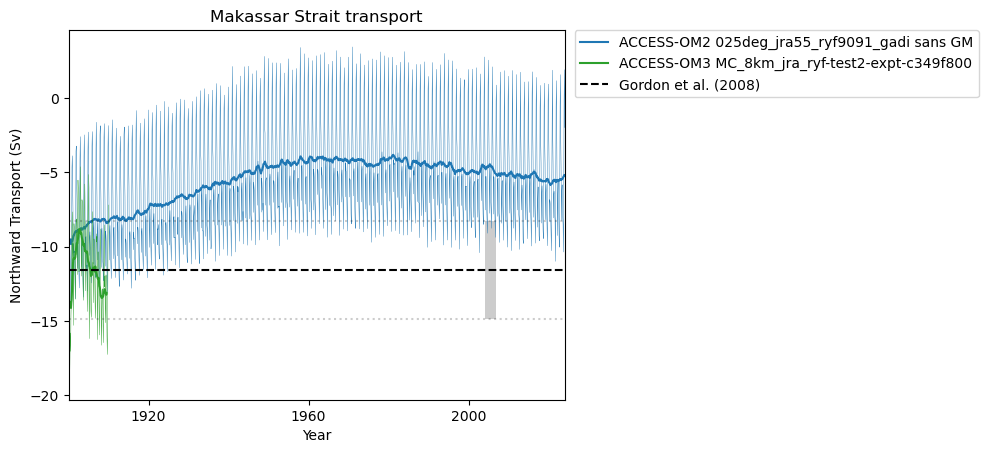

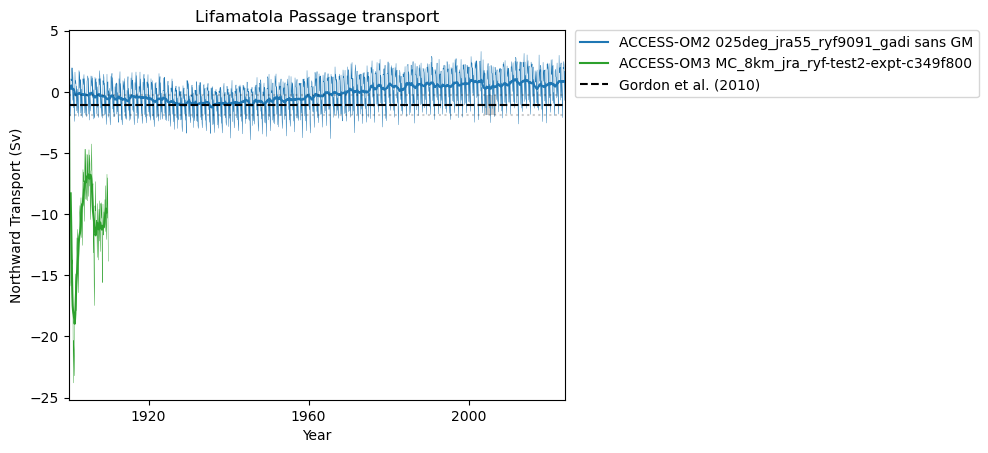

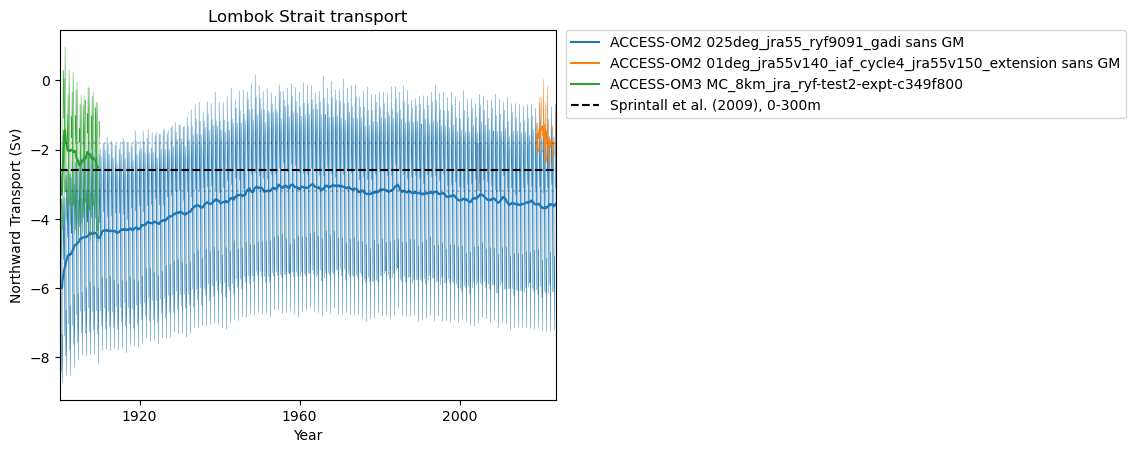

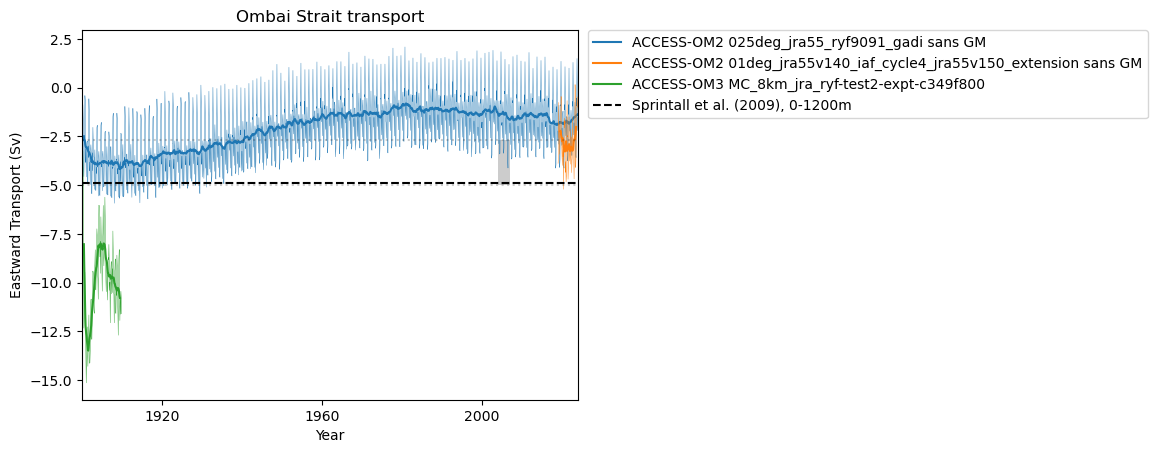

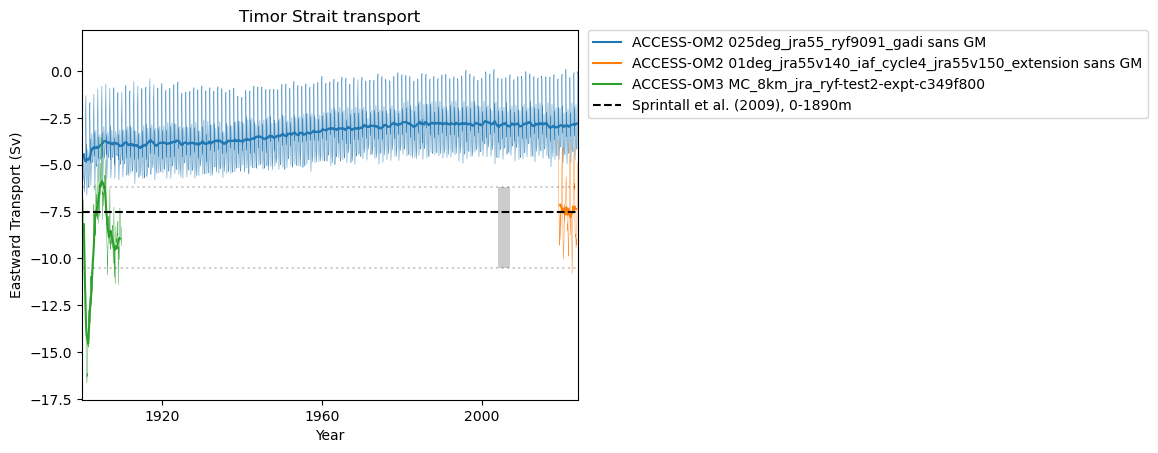

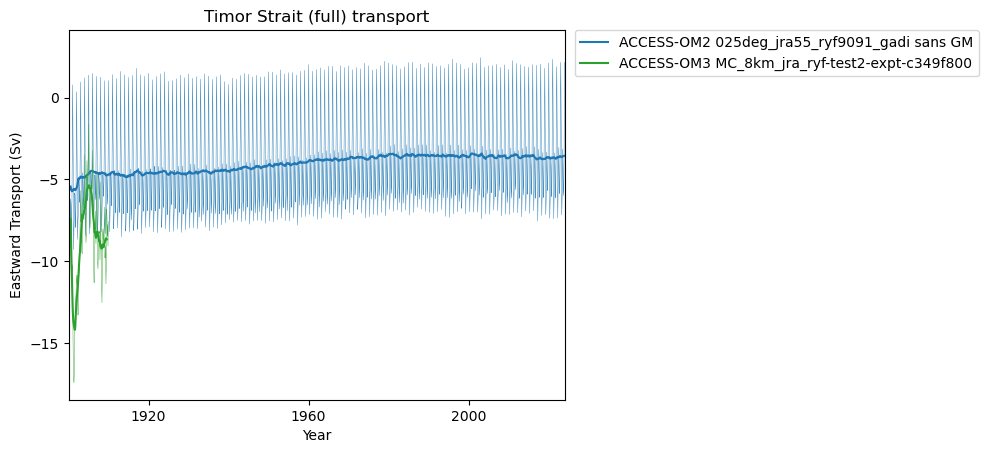

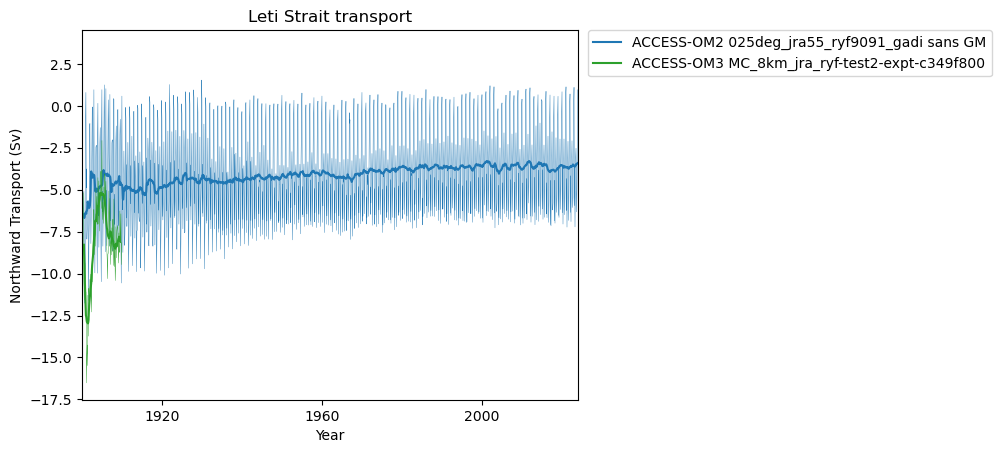

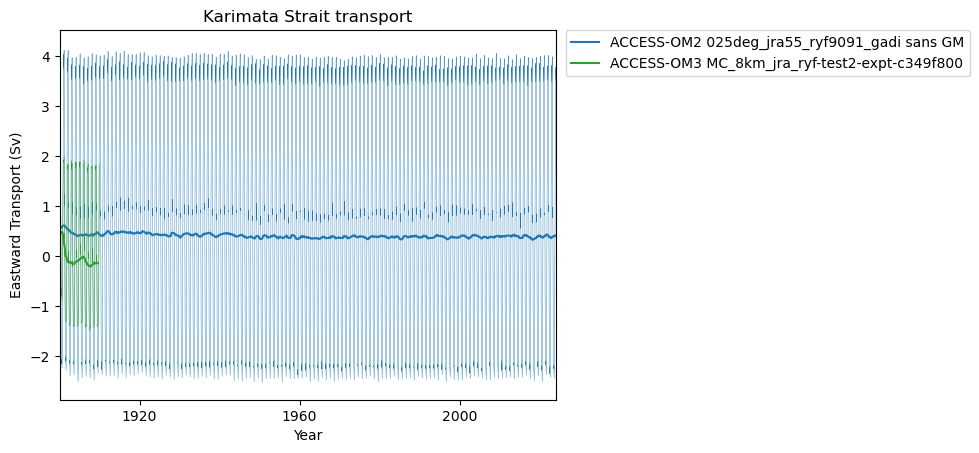

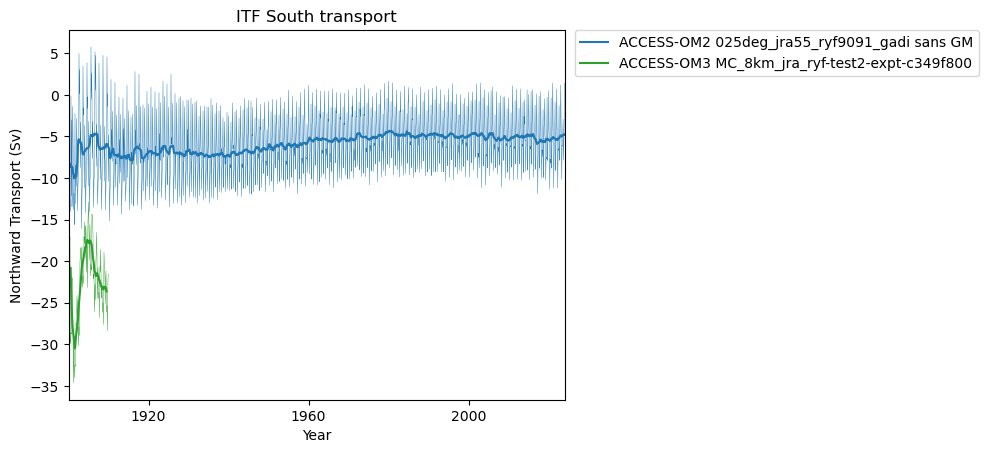

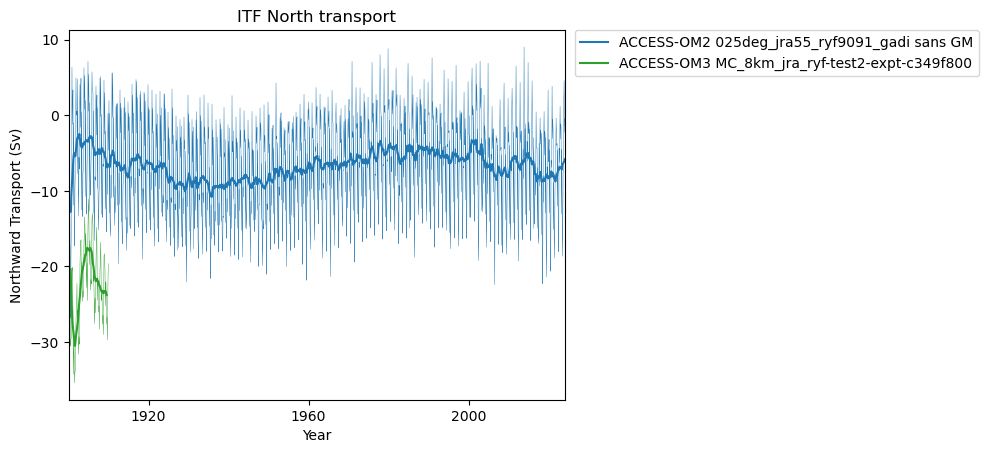

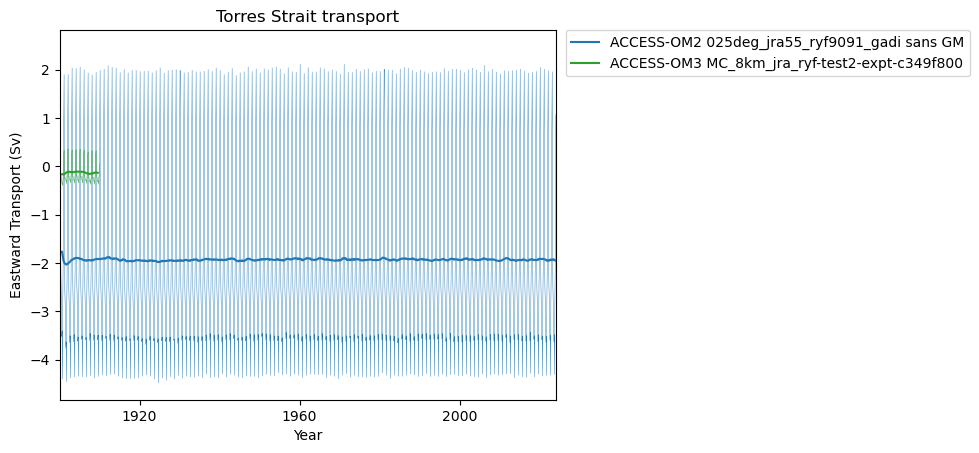

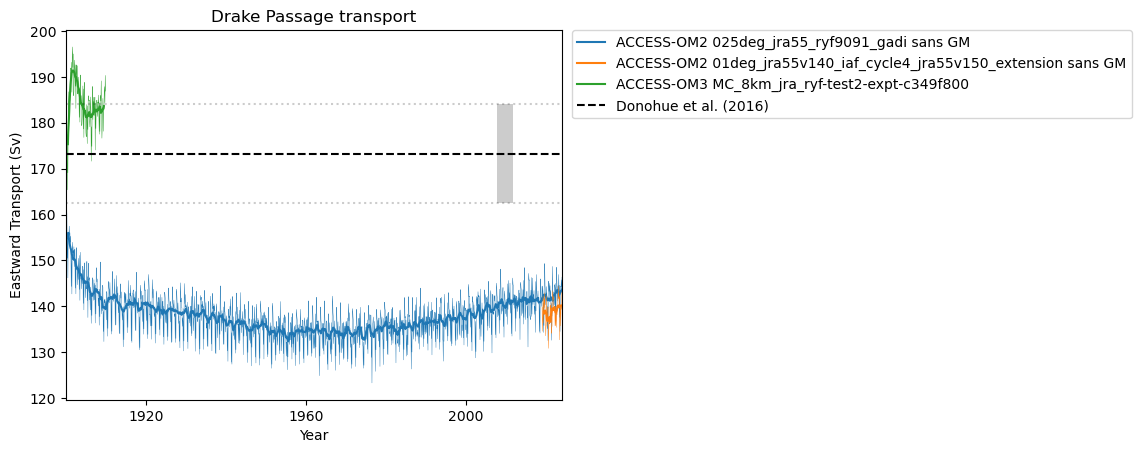

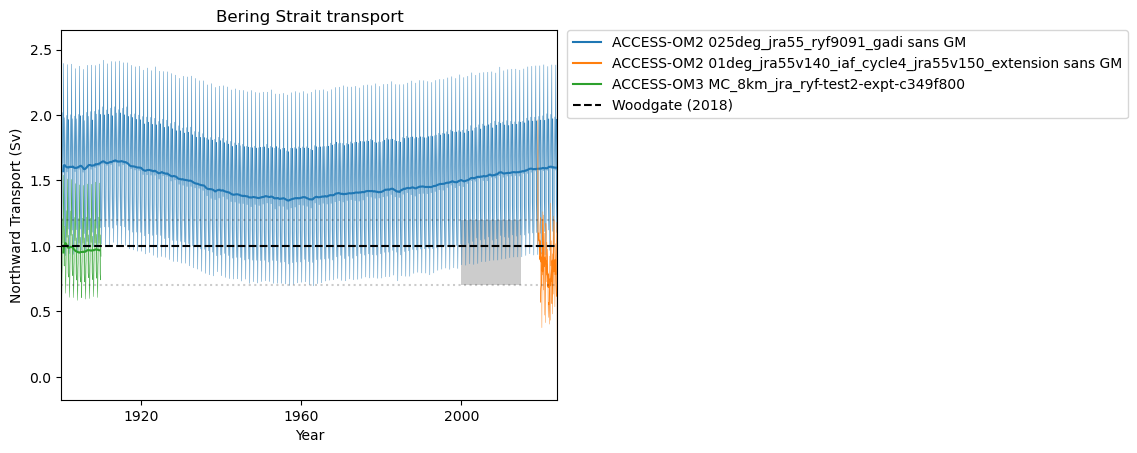

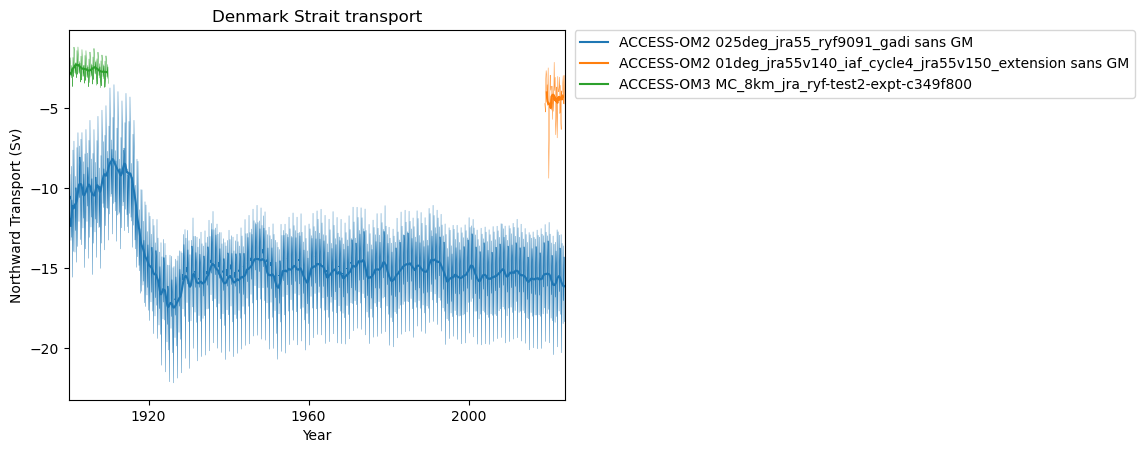

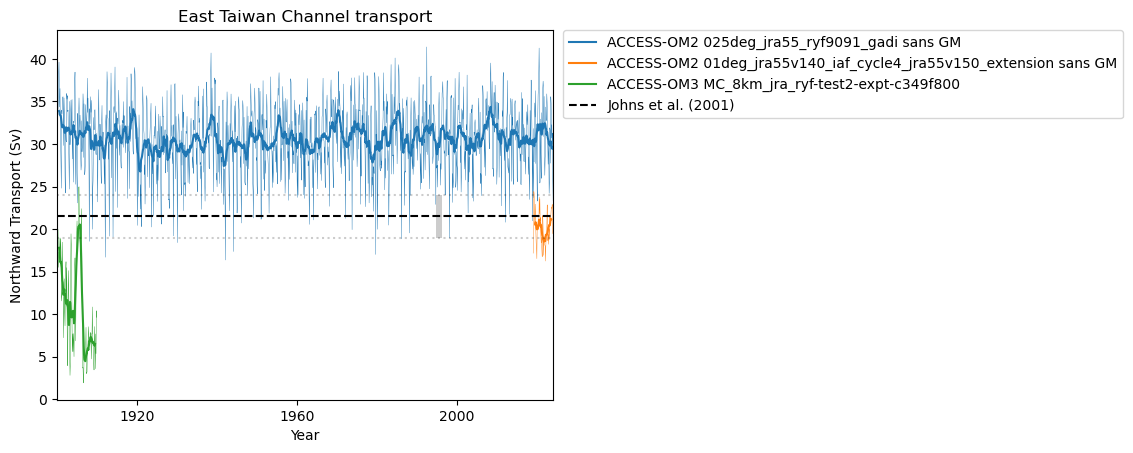

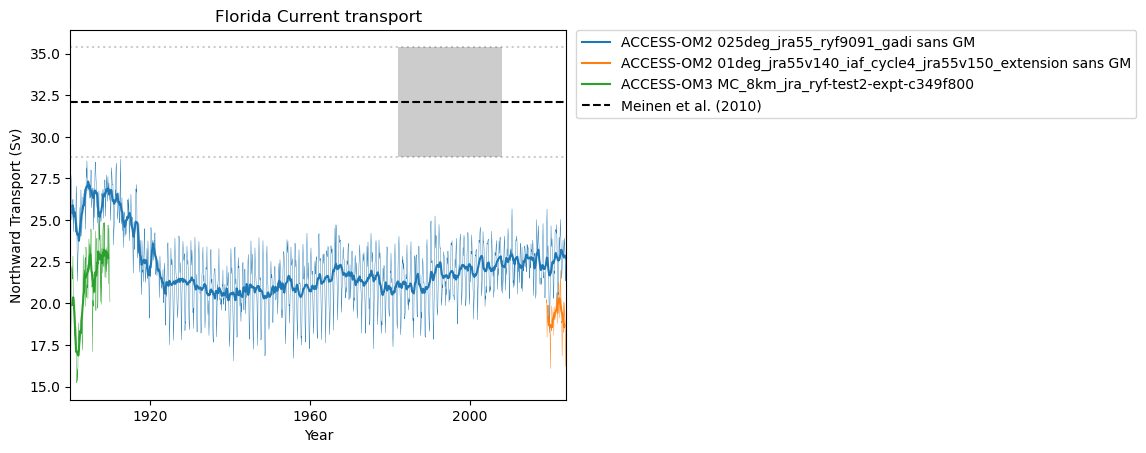

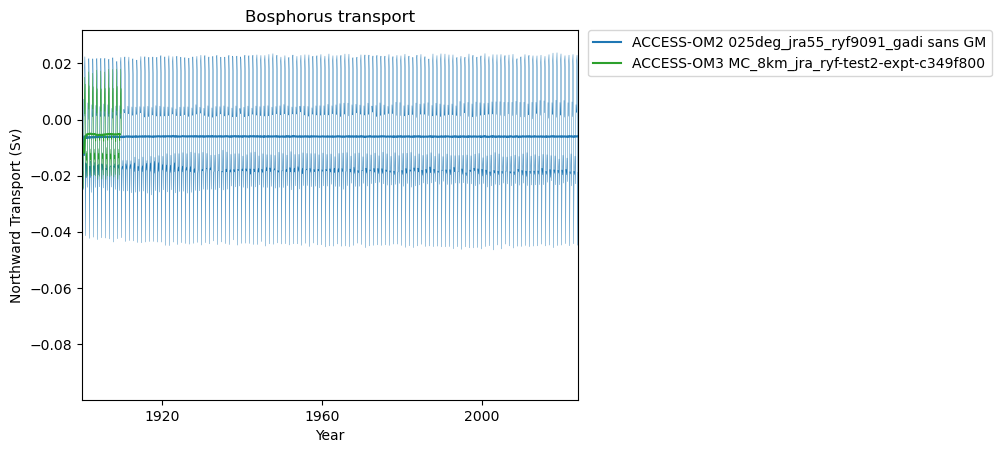

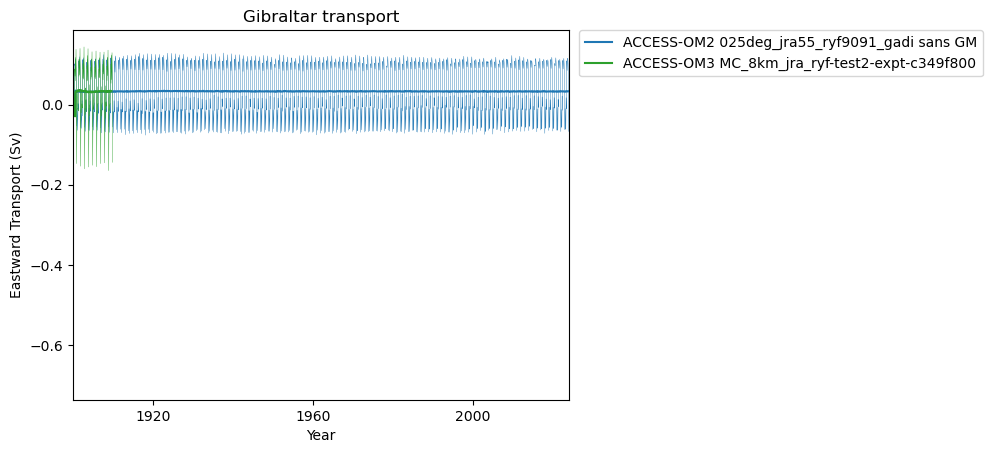

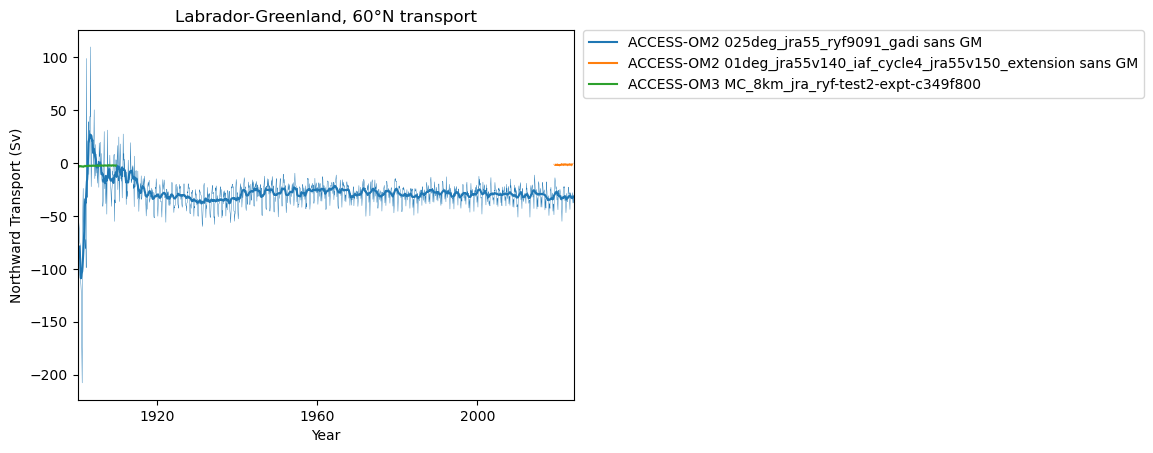

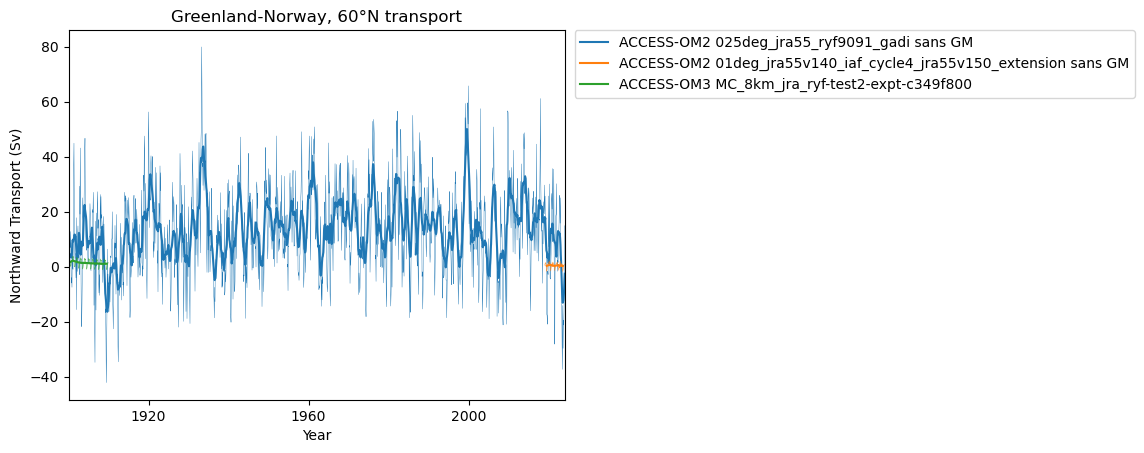

In [45]:
# plot mass transport timeseries (Sv)
# BUG: OM2 GM and submeso transport neglected!

TransTable = [f'{timeslice.start.strftime("%Y-%m-%d")} - {timeslice.stop.strftime("%Y-%m-%d")} mean']
TransTable.append('| Strait | ' + ' | '.join(['OM2 '+n for n in om2exptnames]) + ' | ' + ' | '.join(['OM3 '+n for n in datastores]) + ' | Obs |')
TransTable.append('| ------ | ' + ' | '.join(['--:' for n in om2exptnames]) + ' | ' + ' | '.join(['--:'    for n in datastores]) + ' | --: |')

for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
    plt.figure()

    om2transmeans = []
    _shared_om2_box = None  # feeds the om3-side fallback below, matching original single-om2expt behaviour
    for _om2expt in om2exptnames:
        _fam = _om2_family(_om2expt)
        if strait not in _fam:
            om2transmeans.append(' -- ')  # not resolvable at this OM2 experiment's resolution
            continue
        (_xmin, _xmax, _ymin, _ymax) = _fam[strait]
        if _om2expt == om2exptnames[0]:
            _shared_om2_box = (_xmin, _xmax, _ymin, _ymax)
        if _xmin == _xmax:
            trans = tx_trans_int_z[_om2expt].tx_trans_int_z.sel(xu_ocean=_xmin, method='nearest').sel(yt_ocean=slice(_ymin, _ymax)).sum('yt_ocean')
        elif _ymin == _ymax:
            trans = ty_trans_int_z[_om2expt].ty_trans_int_z.sel(xt_ocean=slice(_xmin, _xmax)).sel(yu_ocean=_ymin, method='nearest').sum('xt_ocean')
        else:
            raise ValueError('Transports are computed only along lines of either constant latitude or longitude')
        trans = trans/1e6/1035  # convert to Sv, rho0 = 1035.0
        trans.plot(linewidth=0.3, color=expt_colors[_om2expt])
        trans.chunk({'time': -1}).rolling(time=min(12, trans.sizes['time']), center=True).mean().plot(label=f"{data_name} {_om2expt} sans GM", linewidth=1.5, color=expt_colors[_om2expt])
        om2transmeanval = trans.sel(time=timeslice_str).mean('time').values
        om2transmeans.append(f'{om2transmeanval:.2f}')
    if _shared_om2_box is not None:
        xmin, xmax, ymin, ymax = _shared_om2_box  # overwrites the om3straits-derived box, as before (using the primary OM2 experiment's own box)

    transmeans = []
    for expt in datastores:
        if "100km" in expt:
            box = om3straits['100km'].get(strait)
            if box is None:
                transmeans.append(' -- ')  # not resolvable at this resolution (e.g. Bosphorus)
                continue
            expt_xmin, expt_xmax, expt_ymin, expt_ymax = box
        else:
            expt_xmin, expt_xmax, expt_ymin, expt_ymax = xmin, xmax, ymin, ymax
        if expt_xmin == expt_xmax:
            trans = om3vars['umo_2d'][expt].umo_2d.sel(xq=expt_xmin, method='nearest').sel(yh=slice(expt_ymin, expt_ymax)).sum('yh')
            direction = 'Eastward'
        elif expt_ymin == expt_ymax:
            trans = om3vars['vmo_2d'][expt].vmo_2d.sel(xh=slice(expt_xmin, expt_xmax)).sel(yq=expt_ymin, method='nearest').sum('xh')
            direction = 'Northward'
        else:
            raise ValueError('Transports are computed only along lines of either constant latitude or longitude')
        trans = trans/1e6/1035  # convert to Sv, RHO_0 = 1035.0
        trans.plot(linewidth=0.3, color=expt_colors[expt])
        trans.chunk({'time': -1}).rolling(time=min(12, trans.sizes['time']), center=True).mean().plot(label=f"{model_name} {expt}", linewidth=1.5, color=expt_colors[expt])
        transmeanval = trans.sel(time=timeslice).mean('time').values
        transmeans.append(f'{transmeanval:.2f}')
    
    plt.autoscale(enable=True, axis='x', tight=True)
    try:
        plt.gca().set_xlim(right=date(2023, 12, 31))
    except AttributeError:
        pass

    if strait in obs:
        for ref, d in obs[strait].items():
            if 'depth' in d:
                depths = f", {str(d['depth'][0])}-{str(d['depth'][1])}m"
            else:
                depths = ""
            plt.plot(plt.gca().get_xlim(), [d['value'], d['value']], 'k--', label=f"{ref}{depths}",)
            plt.plot(plt.gca().get_xlim(), [d['hi'], d['hi']], 'k:', alpha=0.2)
            plt.plot(plt.gca().get_xlim(), [d['lo'], d['lo']], 'k:', alpha=0.2)
            plt.gca().fill_between(d['time'],
                                   [d['hi'], d['hi']],
                                   [d['lo'], d['lo']],
                                   color='black', edgecolor=None, alpha=0.2)
            obstransval = d['value']
            obstrans = f'{obstransval:.2f}'
    else:
        obstrans = ' -- '

    plt.title(f"{strait} transport")
    plt.xlabel('Year')
    plt.ylabel(f'{direction} Transport (Sv)')
    plt.legend(fontsize=10, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

    mkmd.savefig(plt.gcf(), "Strait Transports", f"{strait} transport. [GitHub issue: Drake Passage transport](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/1)")

    # Markdown table - note that this assumes a consistent ordering in dict lookup so requires Python 3.7 or later
    # cb: would be safer here to use a ordered dictionary?
    TransTable.append(f'| {strait} | ' + ' | '.join(om2transmeans) + ' | ' + ' | '.join(transmeans) + f' | {obstrans} |')

for trans in TransTable:
    print(trans)

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_21.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.
1879-12-16 - 1909-12-16 mean
| Strait | OM2 025deg_jra55_ryf9091_gadi | OM2 01deg_jra55v140_iaf_cycle4_jra55v150_extension | OM3 MC_8km_jra_ryf-test2-expt-c349f800 | Obs |
| ------ | --: | --: | --: | --: |
| Makassar Strait | -8.60 |  --  | -11.55 | -11.60 |
| Lifamatola Passage | -0.20 |  --  | -10.58 | -1.10 |
| Lombok Strait | -4.82 | nan | -2.2

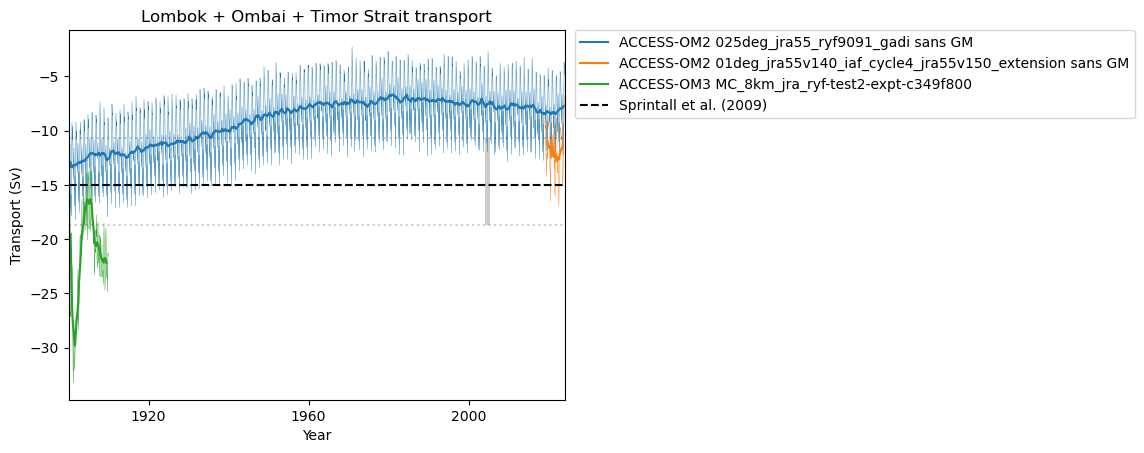

In [46]:
# plot Lombok + Ombai + Timor Strait mass transport timeseries (Sv)
# BUG: OM2 GM and submeso transport neglected!
OM2totals = dict()
OM3totals = dict()
transmeans = []
om2transmeans = []

for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
    if strait in [
        'Lombok Strait',
        'Ombai Strait',
        'Timor Strait'
    ]:
        if strait not in om2straits['025deg']:
            raise KeyError(f"{strait} not in om2straits['025deg']")
        (xmin, xmax, ymin, ymax) = om2straits['025deg'][strait]  # feeds the om3-side loop below, as before
        for _om2expt in om2exptnames:
            _fam = _om2_family(_om2expt)
            if strait not in _fam:
                continue  # not resolvable at this OM2 experiment's resolution
            (_xmin, _xmax, _ymin, _ymax) = _fam[strait]
            if _xmin == _xmax:
                trans = tx_trans_int_z[_om2expt].tx_trans_int_z.sel(xu_ocean=_xmin, method='nearest').sel(yt_ocean=slice(_ymin, _ymax)).sum('yt_ocean')
            elif _ymin == _ymax:
                trans = ty_trans_int_z[_om2expt].ty_trans_int_z.sel(xt_ocean=slice(_xmin, _xmax)).sel(yu_ocean=_ymin, method='nearest').sum('xt_ocean')
            try:
                OM2totals[_om2expt] = OM2totals[_om2expt] + trans/1e6/1035  # convert to Sv, rho0 = 1035.0
            except KeyError:
                OM2totals[_om2expt] = trans/1e6/1035  # convert to Sv, rho0 = 1035.0

        for expt in datastores:
            if xmin == xmax:
                trans = om3vars['umo_2d'][expt].umo_2d.sel(xq=xmin, method='nearest').sel(yh=slice(ymin, ymax)).sum('yh')
            elif ymin == ymax:
                trans = om3vars['vmo_2d'][expt].vmo_2d.sel(xh=slice(xmin, xmax)).sel(yq=ymin, method='nearest').sum('xh')
            try:
                OM3totals[expt] = OM3totals[expt] + trans/1e6/1035  # convert to Sv, RHO_0 = 1035.0
            except KeyError:
                OM3totals[expt] = trans/1e6/1035  # convert to Sv, RHO_0 = 1035.0

plt.figure()

for _om2expt in om2exptnames:
    if _om2expt not in OM2totals:
        om2transmeans.append(' -- ')  # not resolvable at this OM2 experiment's resolution for any sub-strait here
        continue
    OM2total = OM2totals[_om2expt]
    OM2total.plot(linewidth=0.3, color=expt_colors[_om2expt])
    OM2total.chunk({'time': -1}).rolling(time=min(12, OM2total.sizes['time']), center=True).mean().plot(label=f"{data_name} {_om2expt} sans GM", linewidth=1.5, color=expt_colors[_om2expt])
    om2transmeanval = OM2total.sel(time=timeslice_str).mean('time').values
    om2transmeans.append(f'{om2transmeanval:.2f}')

for expt, OM3total in OM3totals.items():
    OM3total.plot(linewidth=0.3, color=expt_colors[expt])
    OM3total.chunk({'time': -1}).rolling(time=min(12, OM3total.sizes['time']), center=True).mean().plot(label=f"{model_name} {expt}", linewidth=1.5, color=expt_colors[expt])
    transmeanval = OM3total.sel(time=timeslice).mean('time').values
    transmeans.append(f'{transmeanval:.2f}')

plt.autoscale(enable=True, axis='x', tight=True)
try:
    plt.gca().set_xlim(right=date(2023, 12, 31))
except AttributeError:
    pass

# Plot obs values (Sv) from Sprintall et al 2009 table 1
obstrans = -15.0
hi = -10.7
lo = -18.7
plt.plot(plt.gca().get_xlim(), [obstrans, obstrans], 'k--', label="Sprintall et al. (2009)")
plt.plot(plt.gca().get_xlim(), [hi, hi], 'k:', alpha=0.2)
plt.plot(plt.gca().get_xlim(), [lo, lo], 'k:', alpha=0.2)
plt.gca().fill_between([date(2004, 1, 10), date(2005, 6, 15)], # use Lombok dates (narrowest range)
                       [hi, hi],
                       [lo, lo],
                       color='black', edgecolor=None, alpha=0.2)

plt.title(f"Lombok + Ombai + Timor Strait transport")
plt.xlabel('Year')
plt.ylabel(f'Transport (Sv)')
plt.legend(fontsize=10, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

mkmd.savefig(plt.gcf(), "Strait Transports", "Lombok + Ombai + Timor Strait transport. [GitHub issue: Indonesian straits](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/16)")

# Markdown table - note that this assumes a consistent ordering in dict lookup so requires Python 3.7 or later
TransTable.append(f'| Lombok + Ombai + Timor Strait | ' + ' | '.join(om2transmeans) + ' | ' + ' | '.join(transmeans) + f' | {obstrans} |')
for trans in TransTable:
    print(trans)

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_22.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.
1879-12-16 - 1909-12-16 mean
| Strait | OM2 025deg_jra55_ryf9091_gadi | OM2 01deg_jra55v140_iaf_cycle4_jra55v150_extension | OM3 MC_8km_jra_ryf-test2-expt-c349f800 | Obs |
| ------ | --: | --: | --: | --: |
| Makassar Strait | -8.60 |  --  | -11.55 | -11.60 |
| Lifamatola Passage | -0.20 |  --  | -10.58 | -1.10 |
| Lombok Strait | -4.82 | nan | -2.2

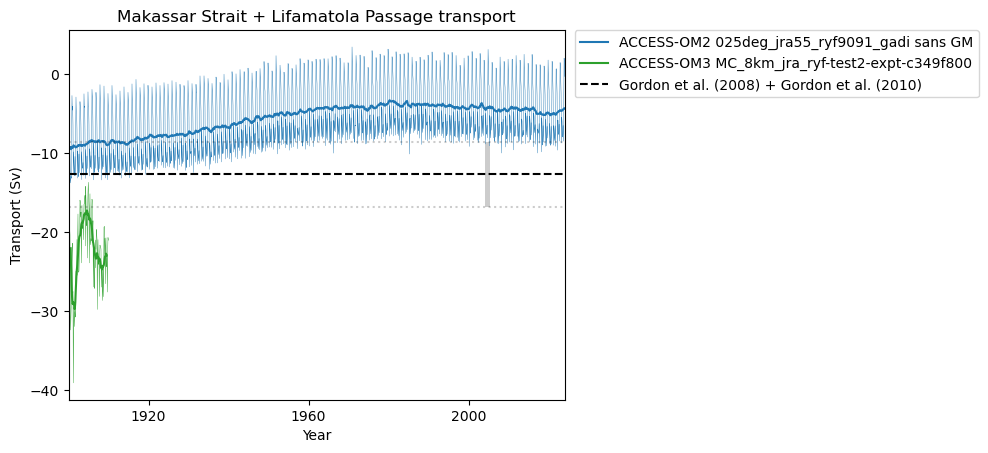

In [47]:
# plot Makassar Strait + Lifamatola Passage mass transport timeseries (Sv)
# BUG: OM2 GM and submeso transport neglected!
OM2totals = dict()
OM3totals = dict()
transmeans = []
om2transmeans = []
for strait, (xmin, xmax, ymin, ymax) in active_om3straits.items():
    if strait in [
        'Makassar Strait',
        'Lifamatola Passage'
    ]:
        if strait not in om2straits['025deg']:
            raise KeyError(f"{strait} not in om2straits['025deg']")
        (xmin, xmax, ymin, ymax) = om2straits['025deg'][strait]  # feeds the om3-side loop below, as before
        for _om2expt in om2exptnames:
            _fam = _om2_family(_om2expt)
            if strait not in _fam:
                continue  # not resolvable at this OM2 experiment's resolution
            (_xmin, _xmax, _ymin, _ymax) = _fam[strait]
            if _xmin == _xmax:
                trans = tx_trans_int_z[_om2expt].tx_trans_int_z.sel(xu_ocean=_xmin, method='nearest').sel(yt_ocean=slice(_ymin, _ymax)).sum('yt_ocean')
            elif _ymin == _ymax:
                trans = ty_trans_int_z[_om2expt].ty_trans_int_z.sel(xt_ocean=slice(_xmin, _xmax)).sel(yu_ocean=_ymin, method='nearest').sum('xt_ocean')
            try:
                OM2totals[_om2expt] = OM2totals[_om2expt] + trans/1e6/1035  # convert to Sv, rho0 = 1035.0
            except KeyError:
                OM2totals[_om2expt] = trans/1e6/1035  # convert to Sv, rho0 = 1035.0

        for expt in datastores:
            if xmin == xmax:
                trans = om3vars['umo_2d'][expt].umo_2d.sel(xq=xmin, method='nearest').sel(yh=slice(ymin, ymax)).sum('yh')
            elif ymin == ymax:
                trans = om3vars['vmo_2d'][expt].vmo_2d.sel(xh=slice(xmin, xmax)).sel(yq=ymin, method='nearest').sum('xh')
            try:
                OM3totals[expt] = OM3totals[expt] + trans/1e6/1035  # convert to Sv, RHO_0 = 1035.0
            except KeyError:
                OM3totals[expt] = trans/1e6/1035  # convert to Sv, RHO_0 = 1035.0



plt.figure()

for _om2expt in om2exptnames:
    if _om2expt not in OM2totals:
        om2transmeans.append(' -- ')  # not resolvable at this OM2 experiment's resolution for any sub-strait here
        continue
    OM2total = OM2totals[_om2expt]
    OM2total.plot(linewidth=0.3, color=expt_colors[_om2expt])
    OM2total.chunk({'time': -1}).rolling(time=min(12, OM2total.sizes['time']), center=True).mean().plot(label=f"{data_name} {_om2expt} sans GM", linewidth=1.5, color=expt_colors[_om2expt])
    om2transmeanval = OM2total.sel(time=timeslice_str).mean('time').values
    om2transmeans.append(f'{om2transmeanval:.2f}')

for expt, OM3total in OM3totals.items():
    OM3total.plot(linewidth=0.3, color=expt_colors[expt])
    OM3total.chunk({'time': -1}).rolling(time=min(12, OM3total.sizes['time']), center=True).mean().plot(label=f"{model_name} {expt}", linewidth=1.5, color=expt_colors[expt])
    transmeanval = OM3total.sel(time=timeslice).mean('time').values
    transmeans.append(f'{transmeanval:.2f}')

plt.autoscale(enable=True, axis='x', tight=True)
try:
    plt.gca().set_xlim(right=date(2023, 12, 31))
except AttributeError:
    pass

# Plot obs values (Sv) from Sprintall et al 2009 table 1
obstrans = -15.0
hi = -10.7
lo = -18.7
obstrans = obs['Makassar Strait']['Gordon et al. (2008)']['value'] + obs['Lifamatola Passage']['Gordon et al. (2010)']['value']
hi =       obs['Makassar Strait']['Gordon et al. (2008)']['hi']    + obs['Lifamatola Passage']['Gordon et al. (2010)']['hi']
lo =       obs['Makassar Strait']['Gordon et al. (2008)']['lo']    + obs['Lifamatola Passage']['Gordon et al. (2010)']['lo']
plt.plot(plt.gca().get_xlim(), [obstrans, obstrans], 'k--', label="Gordon et al. (2008) + Gordon et al. (2010)")
plt.plot(plt.gca().get_xlim(), [hi, hi], 'k:', alpha=0.2)
plt.plot(plt.gca().get_xlim(), [lo, lo], 'k:', alpha=0.2)
plt.gca().fill_between([date(2004, 1, 10), date(2005, 6, 15)], # use Lombok dates (narrowest range)
                       [hi, hi],
                       [lo, lo],
                       color='black', edgecolor=None, alpha=0.2)

plt.title(f"Makassar Strait + Lifamatola Passage transport")
plt.xlabel('Year')
plt.ylabel(f'Transport (Sv)')
plt.legend(fontsize=10, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

mkmd.savefig(plt.gcf(), "Strait Transports", "Makassar Strait + Lifamatola Passage transport. [GitHub issue: Indonesian straits](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/16)")

# Markdown table - note that this assumes a consistent ordering in dict lookup so requires Python 3.7 or later
TransTable.append(f'| Makassar Strait + Lifamatola Passage | ' + ' | '.join(om2transmeans) + ' | ' + ' | '.join(transmeans) + f' | {obstrans} |')
for trans in TransTable:
    print(trans)

mkmd.table("Strait Transports", table=TransTable)

## Plot timeseries of absolute value of transport

This is the sum of the magnitude of transport through each cell at each time, to avoid cancellation in exchange flows, e.g. Gibraltar, Bosphorus. This is double the unidirectional transport if the total transport is zero.

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_23.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_24.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_25.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_26.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_27.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_28.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


... (10 outputs left out)

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_39.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_40.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_41.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports_42.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/StraitTransports.md successfully.
1879-12-16 - 1909-12-16 mean
| Strait | OM2 025deg_jra55_ryf9091_gadi | OM2 01deg_jra55v140_iaf_cycle4_jra55v150_extension | OM3 MC_8km_jra_ryf-test2-expt-c349f800 | Obs |
| ------ | --: | --: | --: | --: |
| Makassar Strait | 10.37 |  --  | 12.98 |  --  |
| Lifamatola Passage | 6.91 |  --  | 15.74 |  --  |
| Lombok Strait | 4.36 | nan | 2.73 |  -- 

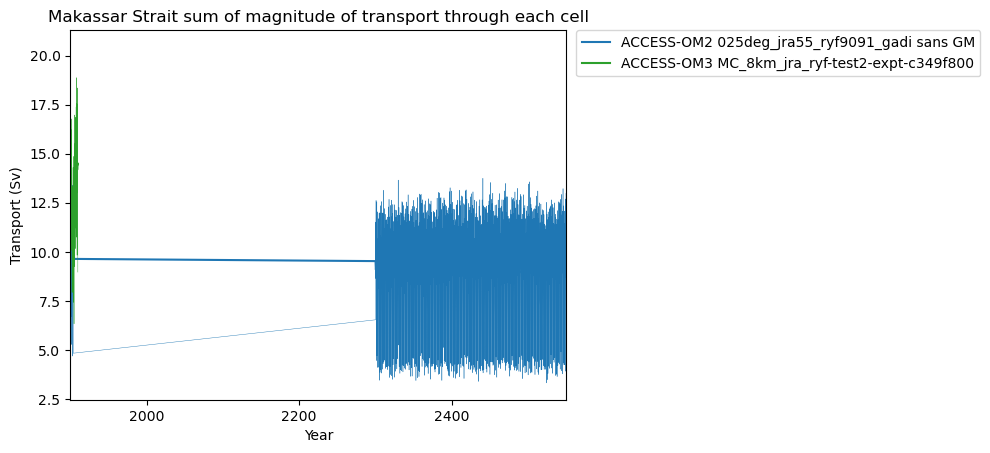

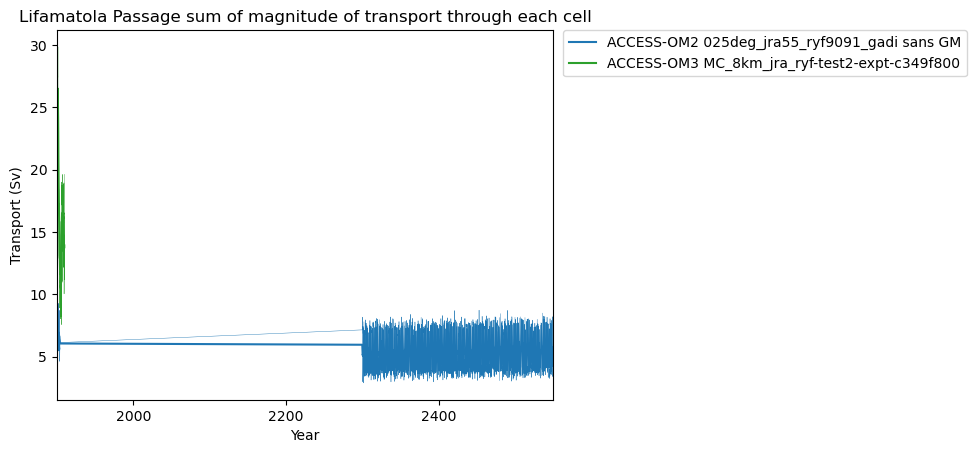

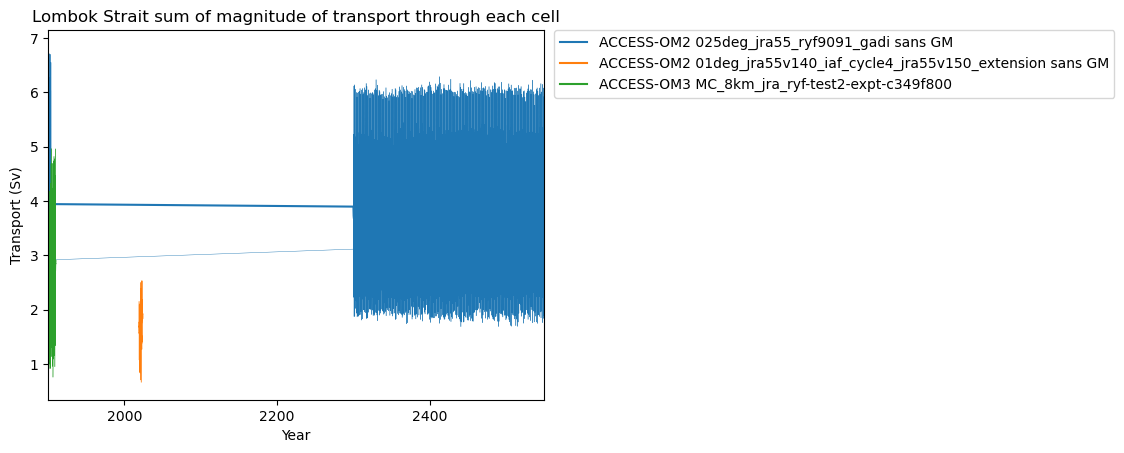

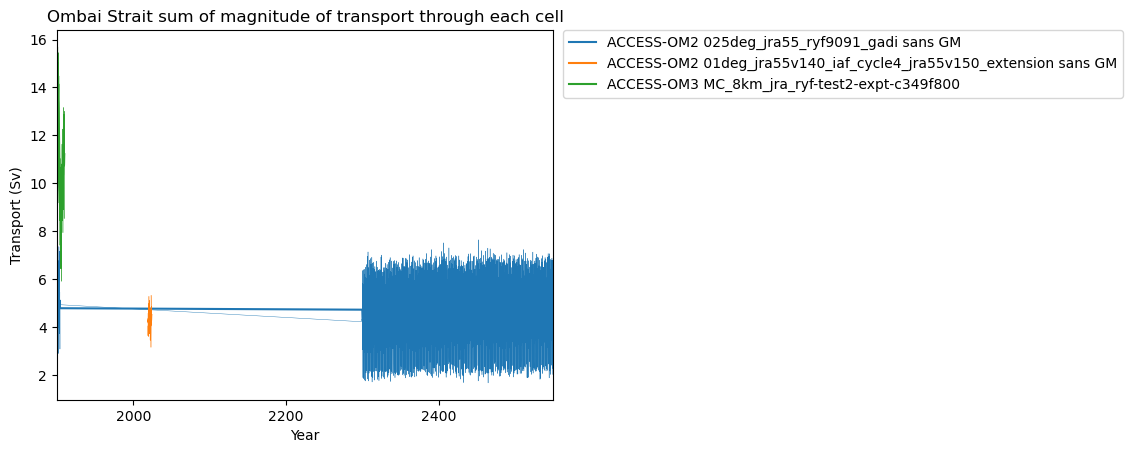

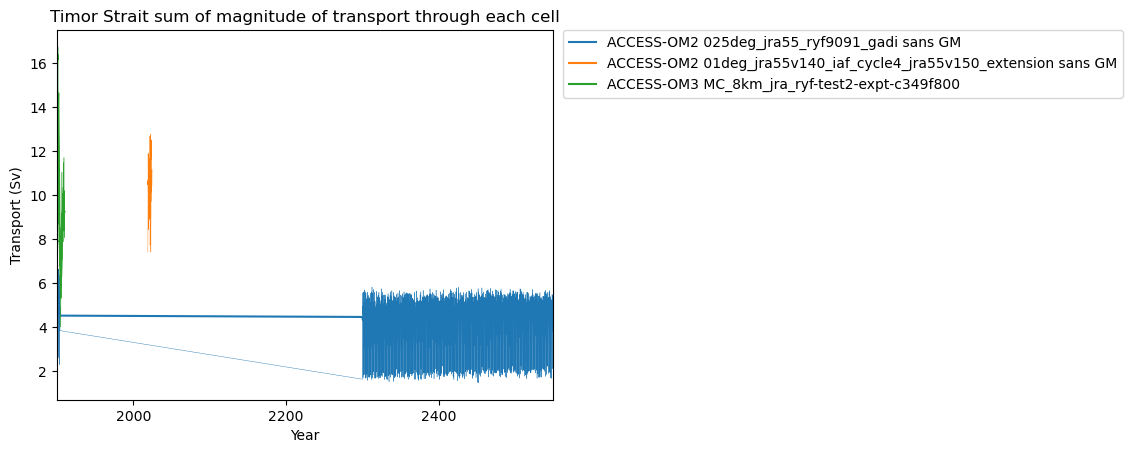

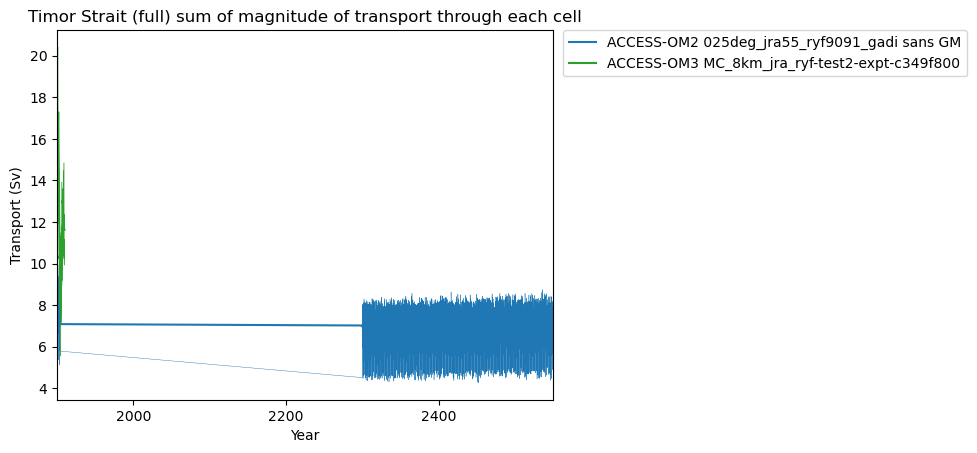

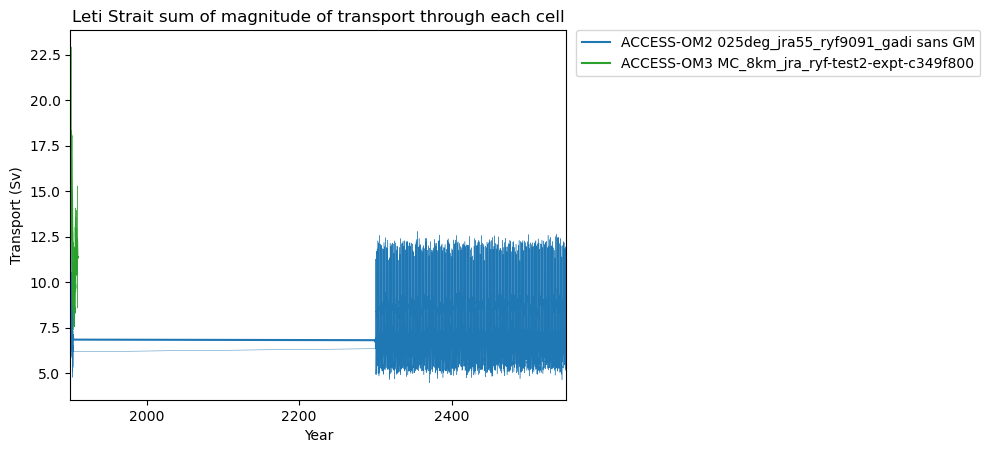

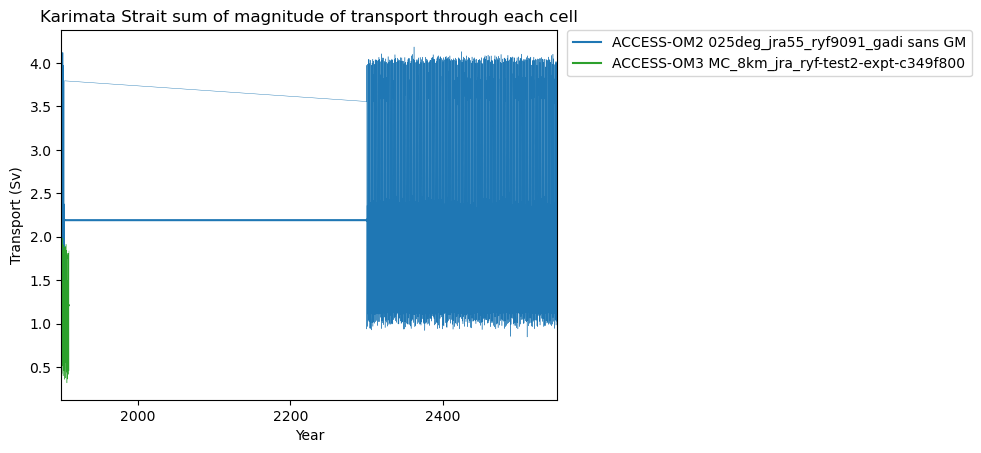

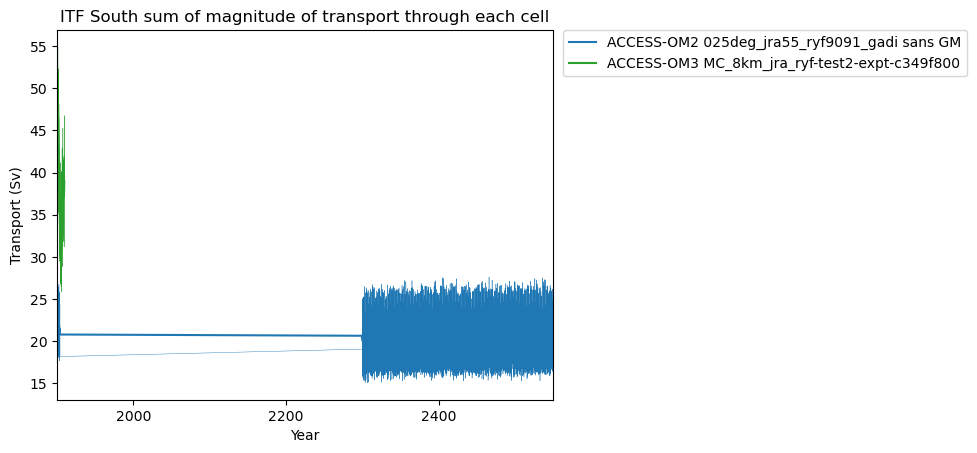

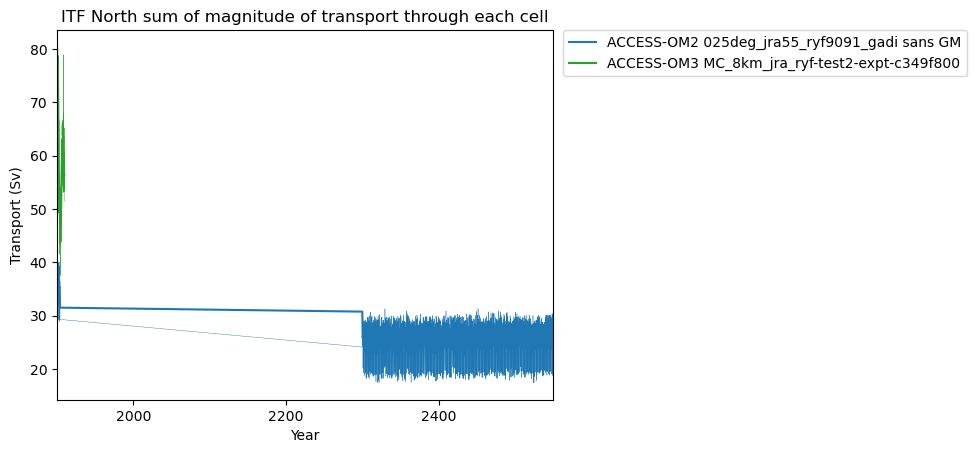

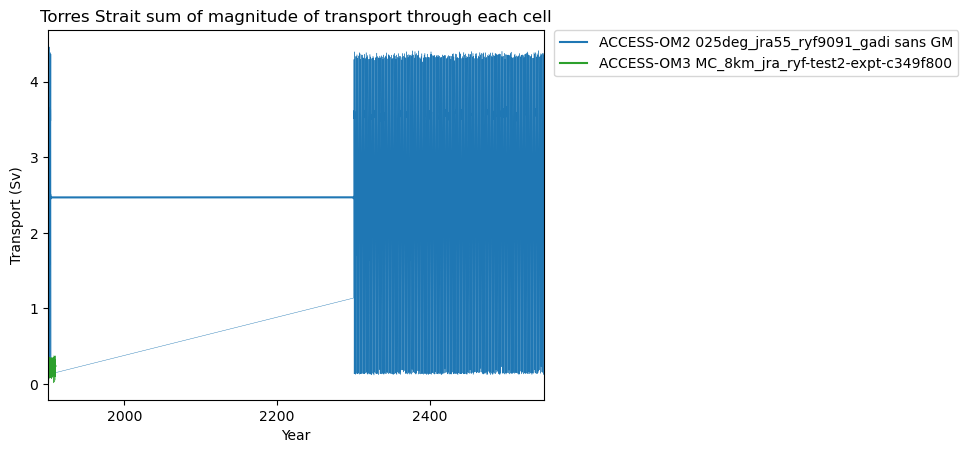

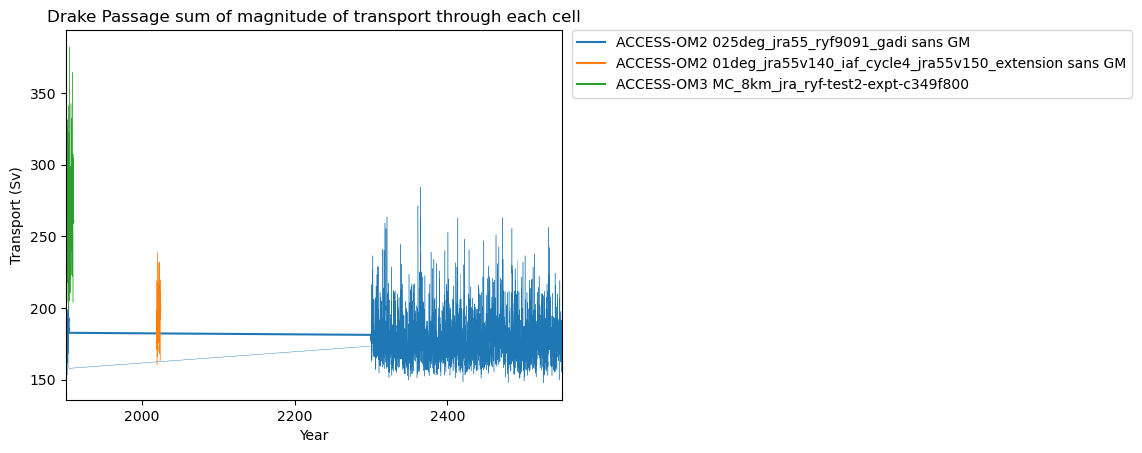

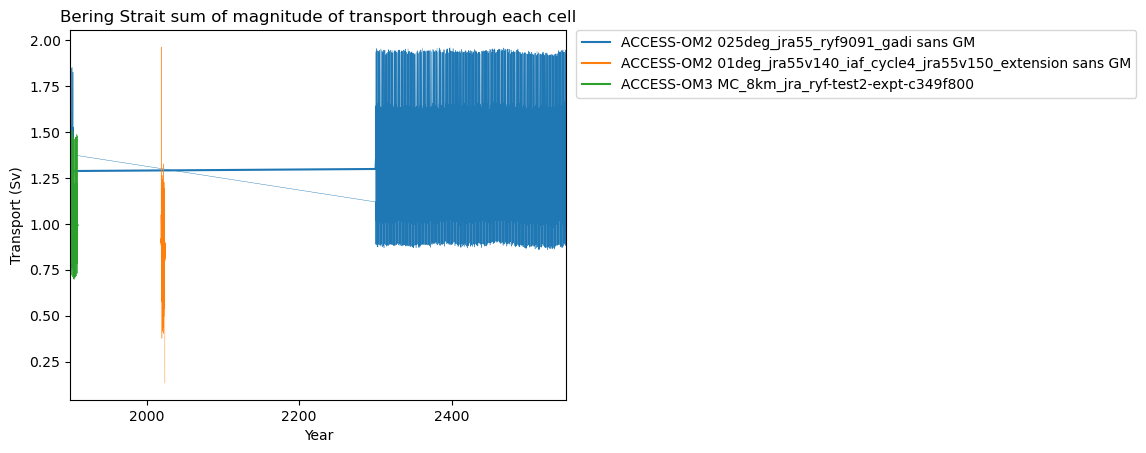

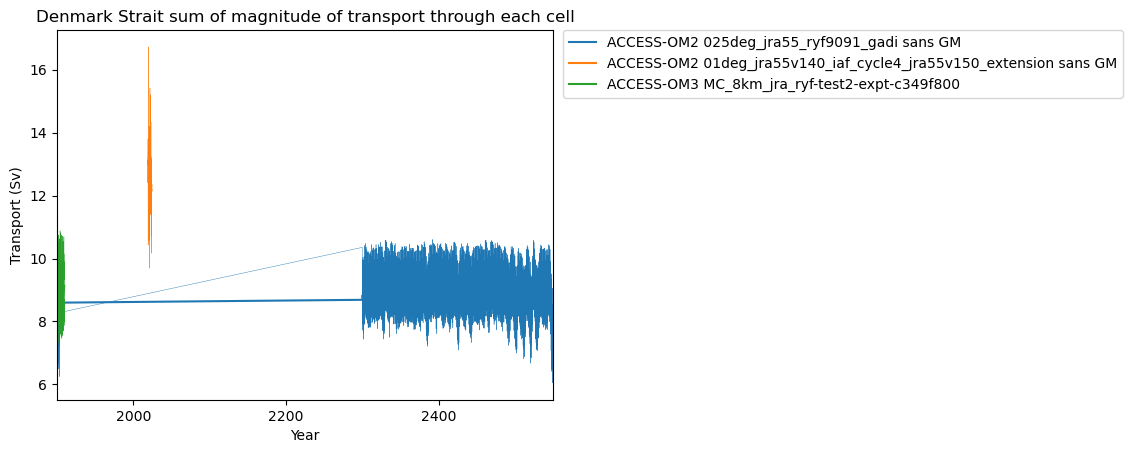

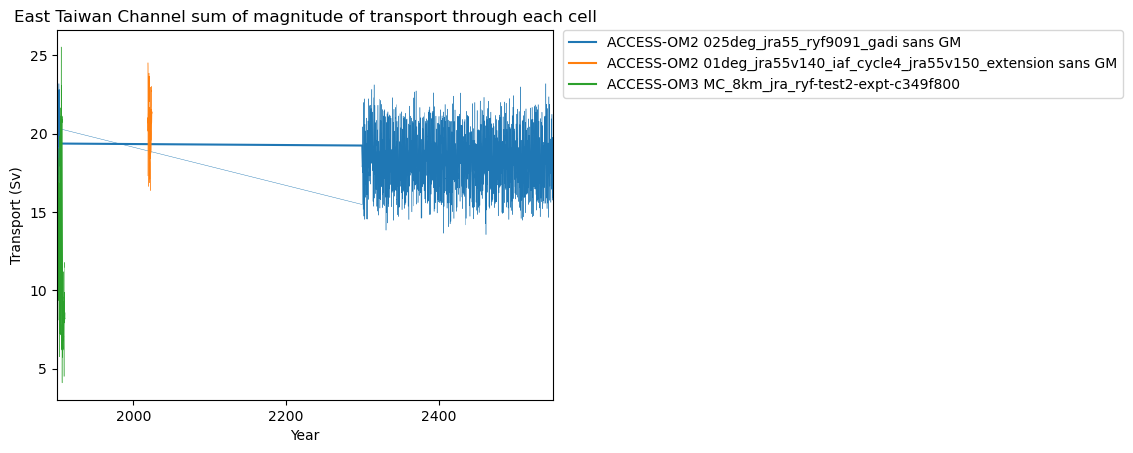

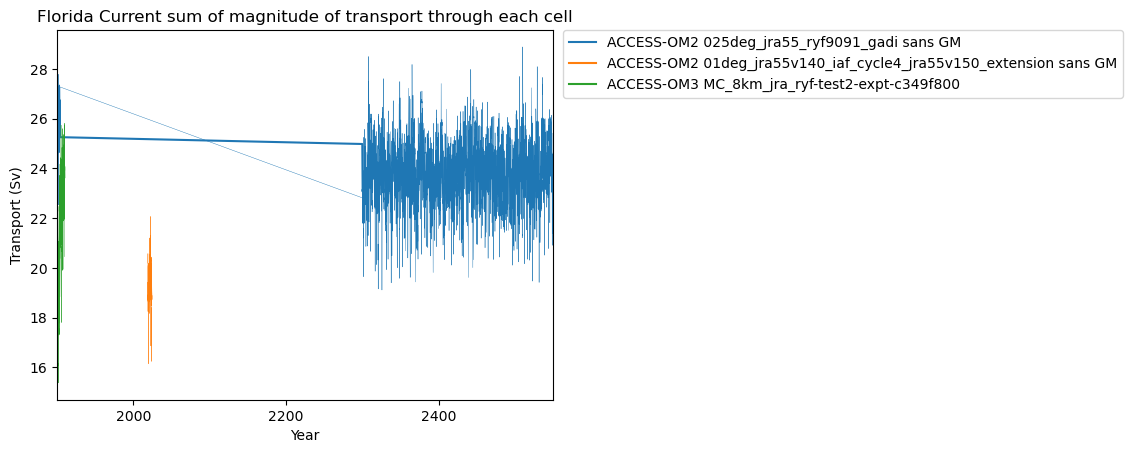

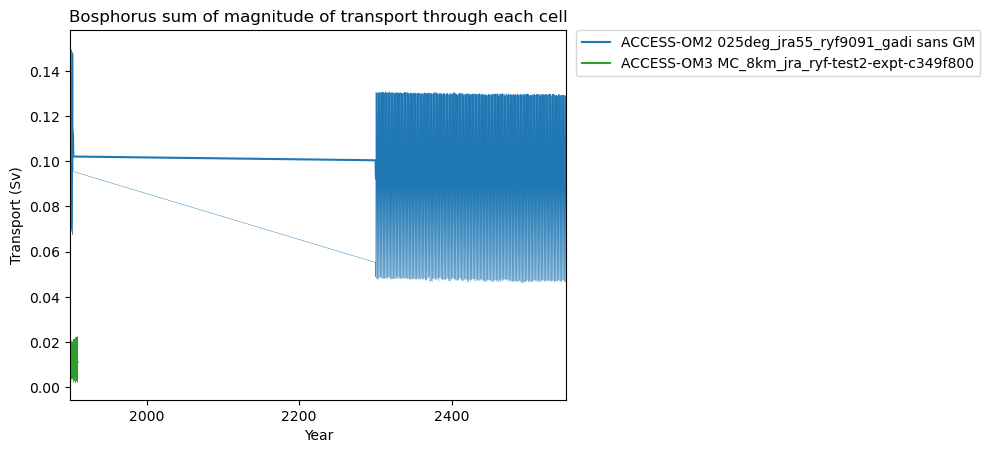

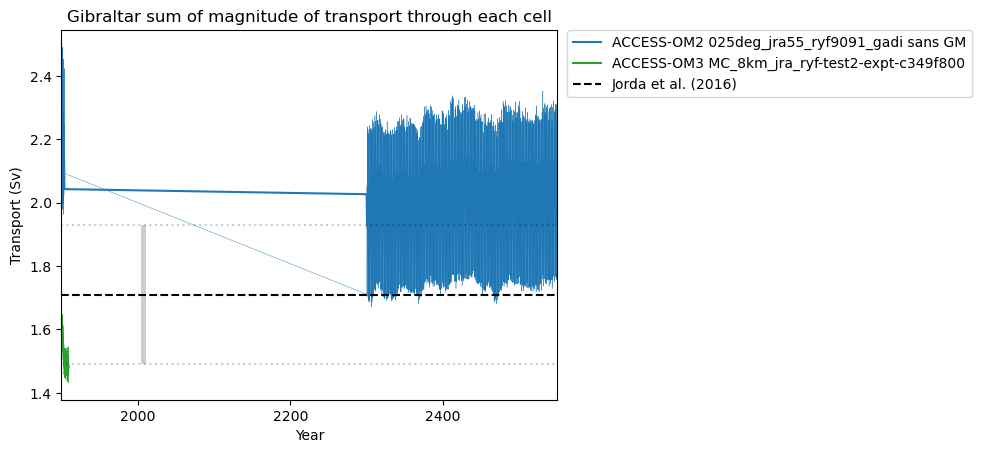

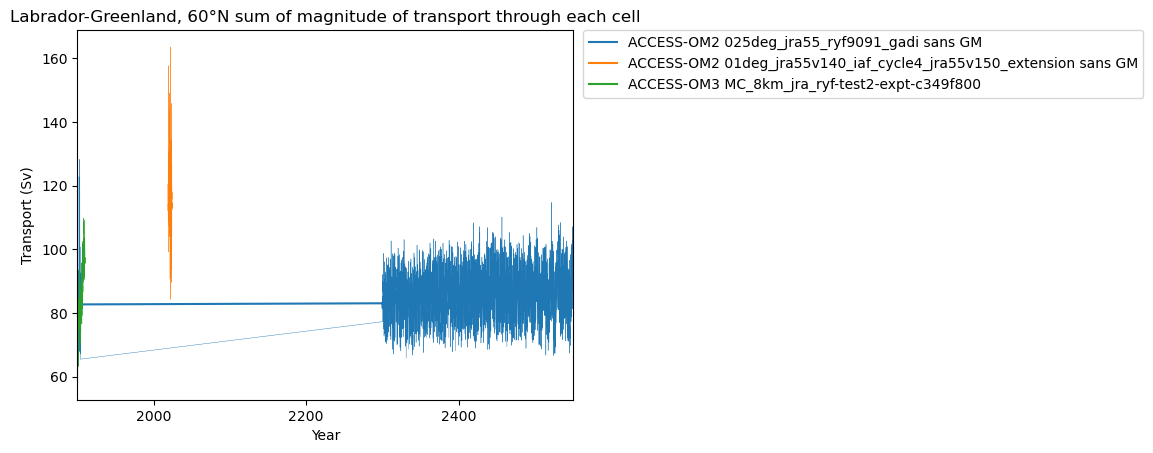

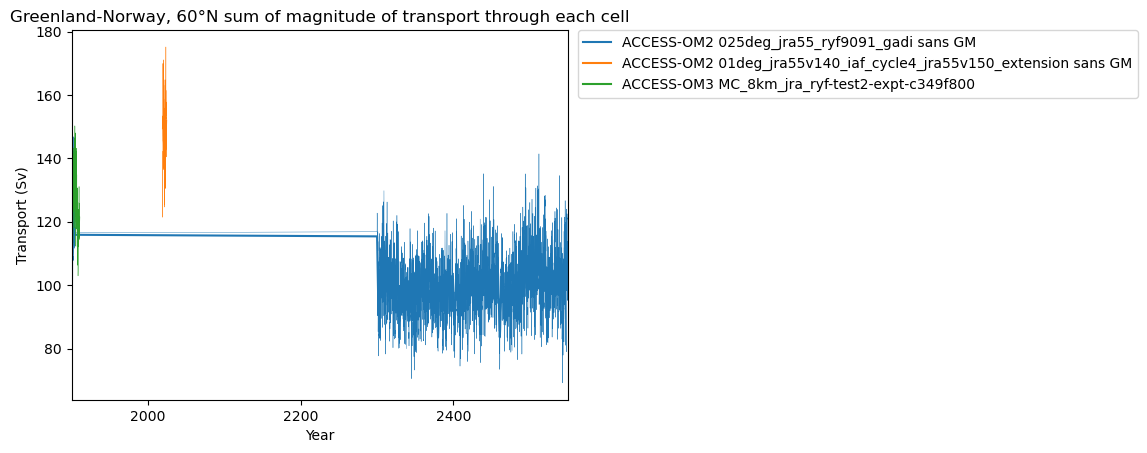

In [48]:
%%time
# plot mass transport absolute value timeseries (Sv)
# BUG: OM2 GM and submeso transport neglected!

# This needs the 3d umo/vmo, which not every experiment saves (e.g. the 100km MCW configs
# only save umo_2d/vmo_2d). If the main experiment lacks them, the figures would show only
# OM2 and be missing the experiment, so skip them (and say so in the page).
_has_3d = lambda expt: expt in om3vars['umo'] and expt in om3vars['vmo']
_skipped_3d = [expt for expt in datastores if not _has_3d(expt)]
_do_abs_plots = _has_3d(om3exptname)
if _skipped_3d:
    print(f"No 3d umo/vmo, so no sum-of-magnitude transport for: {', '.join(_skipped_3d)}")
if not _do_abs_plots:
    _msg = (f"Sum-of-magnitude transport figures were not produced: {om3exptname} does not output "
            "the 3d umo/vmo needed to compute the transport through each cell (only umo_2d/vmo_2d).")
    print(_msg)
    mkmd.table("Sum of magnitude of transport through each cell", [_msg])

TransTable = [f'{timeslice.start.strftime("%Y-%m-%d")} - {timeslice.stop.strftime("%Y-%m-%d")} mean']
TransTable.append('| Strait | ' + ' | '.join(['OM2 '+n for n in om2exptnames]) + ' | ' + ' | '.join(['OM3 '+n for n in datastores]) + ' | Obs |')
TransTable.append('| ------ | ' + ' | '.join(['--:' for n in om2exptnames]) + ' | ' + ' | '.join(['--:'    for n in datastores]) + ' | --: |')

for strait, (xmin, xmax, ymin, ymax) in (active_om3straits.items() if _do_abs_plots else []):
    plt.figure()

    om2transmeans = []
    _shared_om2_box = None  # feeds the om3-side fallback below, matching original single-om2expt behaviour
    for _om2expt in om2exptnames:
        _fam = _om2_family(_om2expt)
        if strait not in _fam:
            om2transmeans.append(' -- ')  # not resolvable at this OM2 experiment's resolution
            continue
        (_xmin, _xmax, _ymin, _ymax) = _fam[strait]
        if _om2expt == om2exptnames[0]:
            _shared_om2_box = (_xmin, _xmax, _ymin, _ymax)
        # sum of |transport| through each cell (full-depth tx_trans/ty_trans, not the depth integral)
        if _xmin == _xmax:
            trans = np.abs(tx_trans[_om2expt].tx_trans.sel(xu_ocean=_xmin, method='nearest').sel(yt_ocean=slice(_ymin, _ymax))).sum('yt_ocean').sum('st_ocean')
        elif _ymin == _ymax:
            trans = np.abs(ty_trans[_om2expt].ty_trans.sel(xt_ocean=slice(_xmin, _xmax)).sel(yu_ocean=_ymin, method='nearest')).sum('xt_ocean').sum('st_ocean')
        else:
            raise ValueError('Transports are computed only along lines of either constant latitude or longitude')
        trans = trans/1e6/1035  # convert to Sv, rho0 = 1035.0
        # trans = trans.sel(time=timeslice)
        trans.plot(linewidth=0.3, color=expt_colors[_om2expt])
        trans.chunk({'time': -1}).rolling(time=min(12, trans.sizes['time']), center=True).mean().plot(label=f"{data_name} {_om2expt} sans GM", linewidth=1.5, color=expt_colors[_om2expt])
        om2transmeanval = trans.sel(time=timeslice_str).mean('time').values
        om2transmeans.append(f'{om2transmeanval:.2f}')
    if _shared_om2_box is not None:
        xmin, xmax, ymin, ymax = _shared_om2_box  # overwrites the om3straits-derived box, as before (using the primary OM2 experiment's own box)

    transmeans = []
    for expt in datastores:
        if not _has_3d(expt):  # 3d umo/vmo are not saved by every experiment (e.g. the 100km configs)
            transmeans.append(' -- ')
            continue
        if "100km" in expt:
            box = om3straits['100km'].get(strait)
            if box is None:
                transmeans.append(' -- ')  # not resolvable at this resolution (e.g. Bosphorus)
                continue
            expt_xmin, expt_xmax, expt_ymin, expt_ymax = box
        else:
            expt_xmin, expt_xmax, expt_ymin, expt_ymax = xmin, xmax, ymin, ymax
        if expt_xmin == expt_xmax:
            trans = np.abs(om3vars['umo'][expt].umo.sel(xq=expt_xmin, method='nearest').sel(yh=slice(expt_ymin, expt_ymax))).sum('yh').sum('rho2_l')
        elif expt_ymin == expt_ymax:
            trans = np.abs(om3vars['vmo'][expt].vmo.sel(xh=slice(expt_xmin, expt_xmax)).sel(yq=expt_ymin, method='nearest')).sum('xh').sum('rho2_l')
        else:
            raise ValueError('Transports are computed only along lines of either constant latitude or longitude')

        trans = trans/1e6/1035  # convert to Sv, RHO_0 = 1035.0
        trans.plot(linewidth=0.3, color=expt_colors[expt])
        trans.chunk({'time': -1}).rolling(time=min(12, trans.sizes['time']), center=True).mean().plot(label=f"{model_name} {expt}", linewidth=1.5, color=expt_colors[expt])
        transmeanval = trans.sel(time=timeslice).mean('time').values
        transmeans.append(f'{transmeanval:.2f}')
    
    plt.autoscale(enable=True, axis='x', tight=True)

    if strait in absobs:
        for ref, d in absobs[strait].items():
            if 'depth' in d:
                depths = f", {str(d['depth'][0])}-{str(d['depth'][1])}m"
            else:
                depths = ""
            plt.plot(plt.gca().get_xlim(), [d['value'], d['value']], 'k--', label=f"{ref}{depths}",)
            plt.plot(plt.gca().get_xlim(), [d['hi'], d['hi']], 'k:', alpha=0.2)
            plt.plot(plt.gca().get_xlim(), [d['lo'], d['lo']], 'k:', alpha=0.2)
            plt.gca().fill_between(d['time'],
                                   [d['hi'], d['hi']],
                                   [d['lo'], d['lo']],
                                   color='black', edgecolor=None, alpha=0.2)
            obstransval = d['value']
            obstrans = f'{obstransval:.2f}'
    else:
        obstrans = ' -- '

    plt.title(f"{strait} sum of magnitude of transport through each cell")
    plt.xlabel('Year')
    plt.ylabel(f'Transport (Sv)')
    plt.legend(fontsize=10, loc = 'upper left', bbox_to_anchor = (1.02,1), borderaxespad=0)

    mkmd.savefig(plt.gcf(), "Sum of magnitude of transport through each cell", f"{strait} sum of magnitude of transport through each cell. [GitHub issue: Restrict Gibraltar Strait flow](https://github.com/ACCESS-NRI/access-om3-configs/issues/1520)")

    # Markdown table - note that this assumes a consistent ordering in dict lookup so requires Python 3.7 or later
    # cb: would be safer here to use a ordered dictionary?
    TransTable.append(f'| {strait} | ' + ' | '.join(om2transmeans) + ' | ' + ' | '.join(transmeans) + f' | {obstrans} |')

for trans in TransTable:
    print(trans)

In [49]:
client.close()